# DisplacedVertex ATLAS-standard response and confusion-matrix plots — FPR = 0.01

This notebook uses the DisplacedVertex FPR operating point produced by
`DisplacedVertex_results_tune.py`:

- primary input: `tpr_at_target_fpr.csv`;
- operating point: **FPR ≤ 0.01**;
- model ranking: **highest TPR** at that common FPR;
- global confusion matrix: exact saved `tn`, `fp`, `fn`, `tp` values from the
  target-FPR table;
- response and per-sample matrices: the same selected global threshold, with
  the ATLAS-standard headers and sample labels.

`accuracy_at_target_fpr.csv` is deliberately not used: it is not an output file
of the DisplacedVertex evaluator. The corresponding evaluator output is named
`tpr_at_target_fpr.csv`.


In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

try:
    get_ipython().run_line_magic("matplotlib", "inline")
except NameError:
    pass

try:
    import mplhep as hep
except ImportError as exc:
    raise ImportError(
        "This notebook requires mplhep for the exact ATLAS plotting style. "
        "Install it in the notebook environment, for example with `pip install mplhep`."
    ) from exc

# Directory produced by DisplacedVertex_results_tune.py.
OUTDIR = Path("onnx_eval_compare_displaced_vertex")
PLOT_PAYLOAD_NAME = "plot_payload.pkl"

# Write PNG figures into OUTDIR / "plots".
SAVE_ATLAS_FIGURES = False
ATLAS_PLOTS_DIR = OUTDIR / "plots"

# Required operating point. The selected threshold is the lowest threshold with
# achieved FPR <= this value, hence the highest TPR allowed by the FPR limit.
BEST_TARGET_FPR = 0.01

# None: plot "__all__", all requested named samples that are available, then any
# additional samples in the payload. Alternatively, provide an explicit list.
PLOT_SAMPLES = None

# Number of bins after rebinning score histograms for display.
N_RESPONSE_BINS = 40

plt.rcParams["figure.dpi"] = 120
pd.set_option("display.max_columns", 200)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 220)

if SAVE_ATLAS_FIGURES:
    ATLAS_PLOTS_DIR.mkdir(parents=True, exist_ok=True)


In [44]:
# Literal ATLAS sample labels requested for the DisplacedVertex plots.
SAMPLE_LABELS = {
    "__all__": r"validation  @  $<\mu>=200$",
    "vertex_a_mumu_m100_ctau5000_mu200": r"$a \rightarrow \mu\mu \, (m_a=100 \, \rm{GeV}) \, @ \, <\mu>=200$",
    "vertex_a_mumu_m10_ctau500_mu200":   r"$a \rightarrow \mu\mu \, (m_a=10 \, \rm{GeV}) \, @ \, <\mu>=200$",
    "vertex_a_mumu_m20_ctau500_mu200":   r"$a \rightarrow \mu\mu \, (m_a=20 \, \rm{GeV}) \, @ \, <\mu>=200$",
    "vertex_a_mumu_m2_ctau100_mu200":    r"$a \rightarrow \mu\mu \, (m_a=2 \, \rm{GeV}) \, @ \, <\mu>=200$",
    "vertex_a_mumu_m4_ctau100_mu200":    r"$a \rightarrow \mu\mu \, (m_a=4 \, \rm{GeV}) \, @ \, <\mu>=200$",
    "vertex_a_mumu_m50_ctau1000_mu200":  r"$a  \rightarrow \mu\mu \, (m_a=50 \, \rm{GeV}) \, @ \, <\mu>=200$",
    "vertex_a_mumu_m6_ctau100_mu200":    r"$a \rightarrow \mu\mu \, (m_a=6 \, \rm{GeV}) \, @ \, <\mu>=200$",
    "vertex_a_mumu_m8_ctau500_mu200":    r"$a \rightarrow \mu\mu \, (m_a=8 \, \rm{GeV}) \, @ \, <\mu>=200$",
    "vertex_Haa4mu_m10_ctau500_mu200":   r"$H \rightarrow aa \rightarrow 4\mu \, (m_a=10 \, \rm{GeV}) \, @ \, <\mu>=200$",
    "vertex_Haa4mu_m4_ctau200_mu200":    r"$H \rightarrow aa \rightarrow 4\mu \, (m_a=4 \, \rm{GeV}) \, @ \, <\mu>=200$",
    "vertex_Haa4mu_m6_ctau200_mu200":    r"$H \rightarrow aa \rightarrow 4\mu \, (m_a=6 \, \rm{GeV}) \, @ \, <\mu>=200$",
    "vertex_Haa4mu_m8_ctau500_mu200":    r"$H \rightarrow aa \rightarrow 4\mu \, (m_a=8 \, \rm{GeV}) \, @ \, <\mu>=200$",
    "vertex_JPSI_mu200" : r"$\mathrm{J}/\psi \rightarrow \mu\mu \, @ \, <\mu>=200$",
    "vertex_Zmumu_mu200": r"$Z \rightarrow \mu \mu \, @ \, <\mu>=200$",
    "vertex_jj_mu200"   : r"$jj \, @ \, <\mu>=200$",
    "vertex_ttbar_mu200": r"$t\bar{t} \, @ \, <\mu>=200$",
}

ATLAS_SAMPLE_LABEL = SAMPLE_LABELS["__all__"]


def sample_label(sample: str) -> str:
    """Return the ATLAS label requested for a payload sample."""
    sample = str(sample)
    if sample in SAMPLE_LABELS:
        return SAMPLE_LABELS[sample]
    return sample.replace("MuonBucketDump_", "").replace("MuonSegmentDump_", "")

In [45]:
def require_csv(path: Path) -> pd.DataFrame:
    if not path.exists():
        raise FileNotFoundError(f"Missing required input file: {path}")
    return pd.read_csv(path)


def safe_filename(s: str) -> str:
    return "".join(
        ch if ch.isalnum() or ch in ("-", "_", ".") else "_"
        for ch in str(s)
    )


def short_name(name: str) -> str:
    """Compact display name, while preserving a meaningful fallback."""
    name = str(name)
    return name.replace("dv_classifier_", "").replace("trial", "t")


def threshold_metrics_from_hist(hist_pos: np.ndarray, hist_neg: np.ndarray, threshold_bin: int) -> dict:
    """Use the same score-bin convention as DisplacedVertex_results_tune.py."""
    hist_pos = np.asarray(hist_pos, dtype=np.int64)
    hist_neg = np.asarray(hist_neg, dtype=np.int64)
    if hist_pos.ndim != 1 or hist_neg.ndim != 1 or hist_pos.size == 0:
        raise ValueError("Expected non-empty, one-dimensional positive and negative score histograms")
    if hist_pos.size != hist_neg.size:
        raise ValueError("Positive and negative score histograms must have the same number of bins")

    n_bins = int(hist_pos.size)
    threshold_bin = int(np.clip(threshold_bin, 0, n_bins - 1))
    tp = int(hist_pos[threshold_bin:].sum())
    fp = int(hist_neg[threshold_bin:].sum())
    fn = int(hist_pos[:threshold_bin].sum())
    tn = int(hist_neg[:threshold_bin].sum())
    total_pos = max(tp + fn, 1)
    total_neg = max(tn + fp, 1)
    total = total_pos + total_neg
    tpr = tp / total_pos
    fpr = fp / total_neg
    accuracy = (tp + tn) / total
    precision = tp / max(tp + fp, 1)
    balanced_accuracy = 0.5 * (tpr + tn / total_neg)
    return {
        "threshold": float(threshold_bin / n_bins),
        "threshold_bin": threshold_bin,
        "tpr": float(tpr),
        "fpr": float(fpr),
        "accuracy": float(accuracy),
        "precision": float(precision),
        "balanced_accuracy": float(balanced_accuracy),
        "tn": tn,
        "fp": fp,
        "fn": fn,
        "tp": tp,
    }


def operating_point_at_target_fpr_from_hist(hist_pos: np.ndarray, hist_neg: np.ndarray, target_fpr: float) -> dict:
    """Mirror the evaluator's FPR working-point rule for a saved score histogram."""
    hist_pos = np.asarray(hist_pos, dtype=np.int64)
    hist_neg = np.asarray(hist_neg, dtype=np.int64)
    if hist_pos.size != hist_neg.size or hist_pos.size == 0:
        raise ValueError("Cannot determine an FPR operating point from incompatible histograms")

    n_bins = int(hist_pos.size)
    fp_from_bin = np.cumsum(hist_neg[::-1])[::-1]
    total_neg = max(int(hist_neg.sum()), 1)
    fpr_from_bin = fp_from_bin / total_neg

    # Lowest valid threshold => highest TPR under the FPR constraint.
    valid_bins = np.flatnonzero(fpr_from_bin <= float(target_fpr))
    threshold_bin = int(valid_bins[0]) if valid_bins.size else n_bins - 1
    out = threshold_metrics_from_hist(hist_pos, hist_neg, threshold_bin)
    out["target_fpr"] = float(target_fpr)
    return out


def operating_point_from_payload(entry: dict, target_fpr: float) -> dict:
    """Return the saved target-FPR point, or reconstruct it from __all__ histograms."""
    all_payload = entry.get("samples", {}).get("__all__")
    if not isinstance(all_payload, dict):
        raise KeyError(f"Model {entry.get('model_id')!r} has no '__all__' sample payload")

    saved_points = all_payload.get("operating_points_at_target_fpr", {})
    if isinstance(saved_points, dict):
        for point in saved_points.values():
            if not isinstance(point, dict):
                continue
            point_target = point.get("target_fpr")
            if point_target is not None and np.isclose(float(point_target), target_fpr, rtol=0.0, atol=1e-12):
                out = dict(point)
                out["target_fpr"] = float(target_fpr)
                return out

    histograms = all_payload.get("histograms", {})
    return operating_point_at_target_fpr_from_hist(
        histograms.get("hist_pos", []), histograms.get("hist_neg", []), target_fpr
    )


summary_path = OUTDIR / "model_summary.csv"
op_fpr_path = OUTDIR / "tpr_at_target_fpr.csv"
plot_payload_path = OUTDIR / PLOT_PAYLOAD_NAME
run_summary_path = OUTDIR / "run_summary.json"

summary_df = require_csv(summary_path)

if not plot_payload_path.exists():
    raise FileNotFoundError(
        f"Missing required plotting payload: {plot_payload_path}\n"
        "Run DisplacedVertex_results_tune.py with plot-payload output enabled."
    )

plot_payload = pd.read_pickle(plot_payload_path)
plot_entries = list(plot_payload.get("models", []))
if not plot_entries:
    raise RuntimeError(f"No model entries are available in {plot_payload_path}")

run_summary = {}
if run_summary_path.exists():
    run_summary = json.loads(run_summary_path.read_text(encoding="utf-8"))

if op_fpr_path.exists():
    # This is the canonical CSV written by DisplacedVertex_results_tune.py.
    op_df = pd.read_csv(op_fpr_path)
    op_source = str(op_fpr_path)
else:
    # Backward-compatible fallback: the payload stores target-FPR points and
    # score histograms, so the 1% FPR point can still be built without any TPR CSV.
    op_rows = []
    for entry in plot_entries:
        try:
            row = operating_point_from_payload(entry, BEST_TARGET_FPR)
        except Exception as exc:
            print(f"Skipping payload operating point for {entry.get('model_id')!r}: {exc}")
            continue
        row.update({
            "model_id": str(entry.get("model_id")),
            "display_name": str(entry.get("display_name", entry.get("model_id"))),
            "short_display_name": short_name(entry.get("display_name", entry.get("model_id"))),
        })
        op_rows.append(row)
    op_df = pd.DataFrame(op_rows)
    op_source = f"saved target-FPR values/histograms in {plot_payload_path}"
    if op_df.empty:
        raise FileNotFoundError(
            f"Neither {op_fpr_path} nor usable target-FPR data in {plot_payload_path} is available."
        )

for df in (summary_df, op_df):
    if "display_name" in df.columns and "short_display_name" not in df.columns:
        df["short_display_name"] = df["display_name"].map(short_name)

for col in (
    "target_fpr", "tpr", "fpr", "threshold", "precision", "accuracy",
    "balanced_accuracy", "tn", "fp", "fn", "tp", "threshold_bin",
):
    if col in op_df.columns:
        op_df[col] = pd.to_numeric(op_df[col], errors="coerce")

if "mean_event_latency_ms_onnxruntime" in summary_df.columns:
    summary_df["mean_event_latency_ms_onnxruntime"] = pd.to_numeric(
        summary_df["mean_event_latency_ms_onnxruntime"], errors="coerce"
    )

required_op_cols = {"model_id", "target_fpr", "fpr", "tpr", "threshold", "tn", "fp", "fn", "tp"}
missing_op_cols = sorted(required_op_cols - set(op_df.columns))
if missing_op_cols:
    raise KeyError(
        f"FPR operating-point data from {op_source} is missing required columns: "
        + ", ".join(missing_op_cols)
    )

print(f"Loaded {len(summary_df)} model-summary rows")
print(f"Loaded {len(op_df)} target-FPR operating-point rows from {op_source}")
print(f"Loaded {len(plot_entries)} plot-payload model entries")
if run_summary:
    print("Metric source:", run_summary.get("metrics_source", "not recorded"))


Loaded 4 model-summary rows
Loaded 8 target-FPR operating-point rows from onnx_eval_compare_displaced_vertex/tpr_at_target_fpr.csv
Loaded 4 plot-payload model entries
Metric source: onnxruntime_hist


## ATLAS plotting helpers

In [55]:
def save_current_figure(name: str) -> None:
    """Save with the same settings used for the ATLAS reference notebook."""
    if SAVE_ATLAS_FIGURES:
        path = ATLAS_PLOTS_DIR / name
        plt.savefig(path, dpi=160, bbox_inches="tight")
        print(f"saved {path}")


def atlas_header_cm(
    ax,
    sample_label="",
    fontsize_atlas=21,
    fontsize_sim=16,
    fontsize_sample=14,
    y_top=1.01,
    sim_x=0.17,
):
    """Draw ATLAS, Simulation label, and the sample label on one line."""
    sample_label = "" if sample_label is None else str(sample_label)
    header_bbox = dict(
        facecolor="white",
        edgecolor="none",
        alpha=0.85,
        pad=1.5,
    )

    ax.text(
        0.00,
        y_top,
        "ATLAS",
        transform=ax.transAxes,
        ha="left",
        va="bottom",
        fontsize=fontsize_atlas,
        fontstyle="italic",
        fontweight="bold",
        bbox=header_bbox,
        clip_on=False,
    )

    ax.text(
        sim_x,
        y_top+0.002,
        "Simulation Preliminary",
        transform=ax.transAxes,
        ha="left",
        va="bottom",
        fontsize=fontsize_sim,
        bbox=header_bbox,
        clip_on=False,
    )

    if sample_label:
        ax.text(
            1.0,
            y_top,
            sample_label,
            transform=ax.transAxes,
            ha="right",
            va="bottom",
            fontsize=fontsize_sample,
            bbox=header_bbox,
            clip_on=False,
        )


def plot_confusion_matrix_atlas(
    cm,
    title=None,
    class_names=("0", "1"),
    true_class_names=("Background", "Signal"),
    predicted_class_names=("Rejected", "Selected"),
    cmap="Blues",
    annotate_fmt=None,
    annotate_fontsize=18,
    normalize=None,
    sample_label=None,
    filename=None,
    figsize=(12, 10),
    dpi=120,
):
    """ATLAS-standard confusion matrix matching the reference notebook."""
    del title  # No plot title: it collides with the ATLAS header.

    cm = np.asarray(cm, dtype=float)

    if normalize == "row":
        row_sums = cm.sum(axis=1, keepdims=True)
        row_sums[row_sums == 0] = 1.0
        cm = cm / row_sums
    elif normalize == "col":
        col_sums = cm.sum(axis=0, keepdims=True)
        col_sums[col_sums == 0] = 1.0
        cm = cm / col_sums
    elif normalize == "all":
        total = cm.sum()
        cm = cm / (total if total else 1.0)
    elif normalize is not None:
        raise ValueError("normalize must be one of None, 'row', 'col', or 'all'")

    if annotate_fmt is None:
        annotate_fmt = "{:.3f}" if normalize else "{:.0f}"

    if sample_label is None:
        sample_label = ""

    with plt.style.context(hep.style.ATLAS):
        fig, ax = plt.subplots(figsize=figsize, dpi=dpi)
        image = ax.imshow(cm, interpolation="nearest", cmap=cmap)
        plt.colorbar(image, ax=ax, fraction=0.046, pad=0.04)

        ax.set_xlabel("Predicted", labelpad=14)
        ax.set_ylabel("True", labelpad=36)
        ax.set_xticks(range(len(predicted_class_names)))
        ax.set_yticks(range(len(true_class_names)))
        ax.set_xticklabels(predicted_class_names)
        ax.set_yticklabels(true_class_names)

        max_value = cm.max() if cm.size and cm.max() > 0 else 1.0
        for i in range(cm.shape[0]):
            for j in range(cm.shape[1]):
                value = cm[i, j]
                colour = "white" if value > 0.5 * max_value else "black"
                ax.text(
                    j, i, annotate_fmt.format(value),
                    ha="center", va="center", color=colour, fontsize=annotate_fontsize,
                )

        ax.grid(False)
        atlas_header_cm(ax, sample_label=sample_label)
        fig.subplots_adjust(left=0.24, right=0.88, bottom=0.18, top=0.82)
        
        ax.yaxis.set_label_coords(-0.25, 1)

        if filename:
            save_current_figure(filename)

    return fig, ax


def plot_best_model_score_response(
    entry,
    sample,
    *,
    threshold=None,
    normalize=True,
    n_plot_bins=100,
    filename=None,
    figsize=(9, 7),
    dpi=120,
):
    """ATLAS-standard score response using the saved histogram payload."""
    sample_payload = entry.get("samples", {}).get(sample)
    if sample_payload is None:
        print(
            f"Sample {sample!r} is not available for "
            f"{entry.get('display_name', entry.get('model_id'))}"
        )
        return None, None

    hist = sample_payload.get("histograms", {})
    hist_signal = np.asarray(hist.get("hist_pos", []), dtype=float)
    hist_background = np.asarray(hist.get("hist_neg", []), dtype=float)

    if hist_signal.size == 0 and hist_background.size == 0:
        print(f"No signal or background score histograms found for sample={sample!r}")
        return None, None
    
    nonempty_sizes = [
        values.size
        for values in (hist_signal, hist_background)
        if values.size > 0
    ]
    
    if len(set(nonempty_sizes)) > 1:
        raise ValueError(
            f"Signal/background histogram sizes differ for sample={sample!r}: "
            f"{hist_signal.size} vs {hist_background.size}"
        )

    # Same rebinning procedure as the reference ATLAS score-response function.
    n_original_bins = nonempty_sizes[0]
    n_plot_bins = min(int(n_plot_bins), n_original_bins)
    if n_plot_bins < 1:
        raise ValueError("n_plot_bins must be at least one")

    original_edges = np.linspace(0.0, 1.0, n_original_bins + 1)
    original_centers = 0.5 * (original_edges[:-1] + original_edges[1:])
    plot_edges = np.linspace(0.0, 1.0, n_plot_bins + 1)

    signal_rebinned = None
    if hist_signal.size > 0:
        signal_rebinned, _ = np.histogram(
            original_centers,
            bins=plot_edges,
            weights=hist_signal,
        )

    background_rebinned = None
    if hist_background.size > 0:
        background_rebinned, _ = np.histogram(
            original_centers,
            bins=plot_edges,
            weights=hist_background,
        )

    y_signal = (
        signal_rebinned.astype(float)
        if signal_rebinned is not None
        else None
    )

    y_background = (
        background_rebinned.astype(float)
        if background_rebinned is not None
        else None
    )

    if normalize:
        if y_signal is not None and y_signal.sum() > 0:
            y_signal /= y_signal.sum()

        if y_background is not None and y_background.sum() > 0:
            y_background /= y_background.sum()
            
        ylabel = "Normalized events"
    else:
        ylabel = "Vertices"

    with plt.style.context(hep.style.ATLAS):
        fig, ax = plt.subplots(figsize=figsize, dpi=dpi)

        if y_signal is not None and y_signal.sum() > 0:
            ax.hist(
                plot_edges[:-1],
                bins=plot_edges,
                weights=y_signal,
                histtype="step",
                linewidth=2.0,
                color="C0",
                label="signal",
            )

        if y_background is not None and y_background.sum() > 0:
            ax.hist(
                plot_edges[:-1],
                bins=plot_edges,
                weights=y_background,
                histtype="step",
                linewidth=2.0,
                color="C1",
                label="background",
            )

        if threshold is not None and np.isfinite(float(threshold)):
            ax.axvline(
                float(threshold),
                linestyle="--",
                linewidth=1.8,
                label=f"threshold = {float(threshold):.2f}",
            )

        ax.set_xlabel("Model score")
        ax.set_ylabel(ylabel)
        ax.set_xlim(0.0, 1.0)
        ax.grid(True, alpha=0.30)
        handles, labels = ax.get_legend_handles_labels()
        if handles:
            ax.legend(handles, labels, frameon=False)
        
        # The ATLAS title block intentionally replaces a conventional axis title.
        atlas_header_cm(ax, sample_label=sample_label(sample))
        fig.subplots_adjust(left=0.16, right=0.96, bottom=0.16, top=0.82)

        if filename:
            save_current_figure(filename)

    return fig, ax

## Select the best model at target FPR = 0.01

The evaluator output for this working point is `tpr_at_target_fpr.csv`. The
operating threshold is the lowest threshold with achieved FPR no larger than
0.01, so it maximizes TPR under the required background-acceptance limit.


In [56]:
# Select the model at the requested target FPR = 0.01.
# Primary criterion: highest TPR at this common FPR working point.
target_values = np.asarray(sorted(op_df["target_fpr"].dropna().unique()), dtype=float)
if target_values.size == 0:
    raise RuntimeError(f"No target_fpr values found in {op_source}")

matches = target_values[np.isclose(target_values, BEST_TARGET_FPR, rtol=0.0, atol=1e-12)]
if matches.size == 0:
    raise RuntimeError(
        f"Requested target_fpr={BEST_TARGET_FPR} is not available in {op_source}. "
        f"Available target_fpr values: {target_values.tolist()}"
    )
best_target_fpr = float(matches[0])

best_candidates = op_df[
    np.isclose(op_df["target_fpr"], best_target_fpr, rtol=0.0, atol=1e-12)
].copy()
best_candidates = best_candidates.dropna(subset=["fpr", "tpr", "threshold"])
if best_candidates.empty:
    raise RuntimeError(
        f"No finite operating-point candidates at target_fpr={best_target_fpr}"
    )

# Diagnostic only. Finite statistics and histogram binning can make the achieved
# FPR slightly smaller than the requested 0.01.
best_candidates["abs_fpr_offset"] = (
    best_candidates["fpr"] - best_target_fpr
).abs()

latency_cols = ["model_id", "mean_event_latency_ms_onnxruntime"]
if all(c in summary_df.columns for c in latency_cols):
    best_candidates = best_candidates.merge(
        summary_df[latency_cols].drop_duplicates("model_id"),
        on="model_id",
        how="left",
    )

# Deterministic tie-breaks after TPR: closest achieved FPR, lower latency, model ID.
sort_cols = ["tpr", "abs_fpr_offset"]
ascending = [False, True]
if "mean_event_latency_ms_onnxruntime" in best_candidates.columns:
    sort_cols.append("mean_event_latency_ms_onnxruntime")
    ascending.append(True)
sort_cols.append("model_id")
ascending.append(True)

best_candidates = best_candidates.sort_values(
    sort_cols, ascending=ascending, na_position="last"
)
best_row = best_candidates.iloc[0]
best_model_id = str(best_row["model_id"])

candidate_name = best_row.get("short_display_name", best_row.get("display_name", best_model_id))
best_name = best_model_id if pd.isna(candidate_name) or not str(candidate_name) else str(candidate_name)
best_threshold = float(best_row["threshold"])

# The global confusion counts below are those evaluated at this exact FPR working point.
display_cols = [
    c for c in [
        "short_display_name", "display_name", "model_id", "layer_type", "target_fpr",
        "tpr", "fpr", "threshold", "threshold_bin", "precision", "accuracy",
        "mean_event_latency_ms_onnxruntime", "tn", "fp", "fn", "tp",
    ] if c in best_candidates.columns
]
print("Best model by highest TPR at target FPR = 0.01")
display(best_candidates[display_cols])
print(f"Selected model: {best_name}")
print(f"Operating threshold: {best_threshold:.8f}")
print(f"Achieved FPR: {float(best_row['fpr']):.8f}")
print(f"Achieved TPR: {float(best_row['tpr']):.8f}")


Best model by highest TPR at target FPR = 0.01


,short_display_name,display_name,model_id,layer_type,target_fpr,tpr,fpr,threshold,threshold_bin,precision,accuracy,mean_event_latency_ms_onnxruntime,tn,fp,fn,tp
1,refit_postpatch_20260630_rank02_t00056,refit_postpatch_20260630_rank02_trial00056,/eos/project-i01/f/fcc-ml/ddicroce/ATLAS_MuonS...,edge_residual,0.01,0.664340,0.010000,0.619465,123893,0.987272,0.814584,0.896632,82962,838,32841,64999
0,refit_postpatch_20260630_rank01_t00103,refit_postpatch_20260630_rank01_trial00103,/eos/project-i01/f/fcc-ml/ddicroce/ATLAS_MuonS...,edge_residual,0.01,0.624080,0.010000,0.955990,191198,0.986462,0.792898,0.969887,82962,838,36780,61060
3,refit_postpatch_20260630_rank04_t00096,refit_postpatch_20260630_rank04_trial00096,/eos/project-i01/f/fcc-ml/ddicroce/ATLAS_MuonS...,edge_residual,0.01,0.622383,0.009988,0.530395,106079,0.986441,0.791990,1.261081,82963,837,36946,60894
2,refit_postpatch_20260630_rank03_t00109,refit_postpatch_20260630_rank03_trial00109,/eos/project-i01/f/fcc-ml/ddicroce/ATLAS_MuonS...,edge_residual,0.01,0.586059,0.010000,0.919695,183939,0.985596,0.772418,0.987532,82962,838,40500,57340


Selected model: refit_postpatch_20260630_rank02_t00056
Operating threshold: 0.61946500
Achieved FPR: 0.01000000
Achieved TPR: 0.66433974


## Build the exact global confusion matrix at FPR ≤ 0.01

Global confusion counts at FPR <= 0.01
               Predicted Rejected  Predicted Selected
True Rejected               82962                 838
True Selected               32841               64999


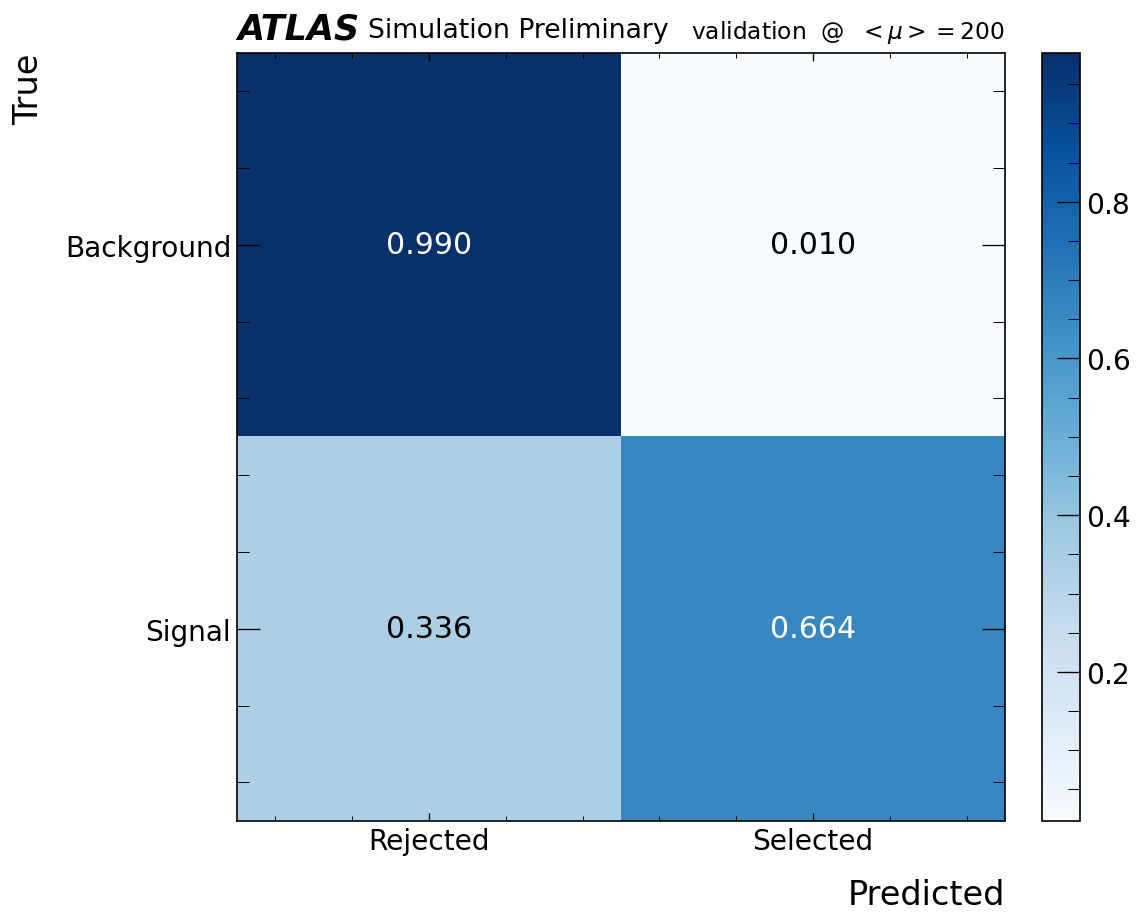

In [57]:
count_cols = ["tn", "fp", "fn", "tp"]
missing_counts = [c for c in count_cols if c not in best_row.index]
if missing_counts:
    raise KeyError(
        "Target-FPR operating-point data is missing confusion-count columns: "
        f"{missing_counts}"
    )
if any(pd.isna(best_row[c]) for c in count_cols):
    raise ValueError("The selected target-FPR operating point has non-finite confusion counts")

# When tpr_at_target_fpr.csv is available, these are the evaluator's exact saved
# counts. The payload fallback has already used the evaluator's histogram rule.
cm_global = np.asarray(
    [
        [int(best_row["tn"]), int(best_row["fp"])],
        [int(best_row["fn"]), int(best_row["tp"])],
    ],
    dtype=np.int64,
)

fpr_tag = f"{best_target_fpr:.6f}".replace(".", "p")
print("Global confusion counts at FPR <= 0.01")
print(pd.DataFrame(
    cm_global,
    index=["True Rejected", "True Selected"],
    columns=["Predicted Rejected", "Predicted Selected"],
))

cm_filename = f"dv_cm_validation.png"
fig, ax = plot_confusion_matrix_atlas(
    cm_global,
    normalize="row",
    class_names=("Rejected", "Selected"),
    sample_label=ATLAS_SAMPLE_LABEL,
    filename=cm_filename,
)

# save png and pdf
plt.savefig(cm_filename)
plt.savefig(cm_filename.replace(".png", ".pdf"))

plt.show()
plt.close(fig)


## Produce ATLAS-standard response and confusion-matrix figures by sample

The merged validation matrix above uses the saved target-FPR operating-point
counts. For every named sample, the same **global threshold** selected at
FPR ≤ 0.01 is applied to its saved score histogram. This preserves a common
working point across all benchmark samples.


In [58]:
def threshold_bin_from_value(threshold: float, n_bins: int) -> int:
    """Match the threshold-bin rule in DisplacedVertex_results_tune.py."""
    return int(
        np.clip(np.floor(float(threshold) * int(n_bins)), 0, int(n_bins) - 1)
    )


def confusion_matrix_from_saved_histogram(sample_payload: dict, threshold: float) -> np.ndarray:
    """Exact integer counts from a saved payload histogram at a fixed threshold."""
    histograms = sample_payload.get("histograms", {})
    hist_pos = np.asarray(histograms.get("hist_pos", []), dtype=np.int64)
    hist_neg = np.asarray(histograms.get("hist_neg", []), dtype=np.int64)

    if hist_pos.size == 0 or hist_neg.size == 0:
        raise ValueError("The saved sample payload does not contain both hist_pos and hist_neg")
    if hist_pos.size != hist_neg.size:
        raise ValueError(
            f"Histogram-size mismatch: hist_pos={hist_pos.size}, hist_neg={hist_neg.size}"
        )

    threshold_bin = threshold_bin_from_value(threshold, hist_pos.size)
    tp = int(hist_pos[threshold_bin:].sum())
    fp = int(hist_neg[threshold_bin:].sum())
    fn = int(hist_pos[:threshold_bin].sum())
    tn = int(hist_neg[:threshold_bin].sum())

    return np.asarray([[tn, fp], [fn, tp]], dtype=np.int64)


plot_by_id = {str(entry.get("model_id")): entry for entry in plot_entries}
best_entry = plot_by_id.get(best_model_id)
if best_entry is None:
    raise RuntimeError(
        f"The selected model_id={best_model_id!r} is absent from {plot_payload_path}. "
        "Rerun DisplacedVertex_results_tune.py so the selected model has a payload entry."
    )

available_samples = list(best_entry.get("samples", {}).keys())
if not available_samples:
    raise RuntimeError("The selected model has no sample payloads")

if PLOT_SAMPLES is None:
    preferred_order = ["__all__", *[s for s in SAMPLE_LABELS if s != "__all__"]]
    selected_samples = [s for s in preferred_order if s in available_samples]
    selected_samples += sorted(s for s in available_samples if s not in selected_samples)
else:
    selected_samples = [str(s) for s in PLOT_SAMPLES if str(s) in available_samples]
    missing_requested_samples = [str(s) for s in PLOT_SAMPLES if str(s) not in available_samples]
    if missing_requested_samples:
        print("Requested samples not found in the payload:", missing_requested_samples)

if not selected_samples:
    raise RuntimeError("No requested samples are available in the selected model payload")

print("Samples to plot:")
for this_sample in selected_samples:
    print(f"  {this_sample}  ->  {sample_label(this_sample)}")

Samples to plot:
  __all__  ->  validation  @  $<\mu>=200$
  vertex_a_mumu_m100_ctau5000_mu200  ->  $a \rightarrow \mu\mu \, (m_a=100 \, \rm{GeV}) \, @ \, <\mu>=200$
  vertex_a_mumu_m10_ctau500_mu200  ->  $a \rightarrow \mu\mu \, (m_a=10 \, \rm{GeV}) \, @ \, <\mu>=200$
  vertex_a_mumu_m20_ctau500_mu200  ->  $a \rightarrow \mu\mu \, (m_a=20 \, \rm{GeV}) \, @ \, <\mu>=200$
  vertex_a_mumu_m2_ctau100_mu200  ->  $a \rightarrow \mu\mu \, (m_a=2 \, \rm{GeV}) \, @ \, <\mu>=200$
  vertex_a_mumu_m4_ctau100_mu200  ->  $a \rightarrow \mu\mu \, (m_a=4 \, \rm{GeV}) \, @ \, <\mu>=200$
  vertex_a_mumu_m50_ctau1000_mu200  ->  $a  \rightarrow \mu\mu \, (m_a=50 \, \rm{GeV}) \, @ \, <\mu>=200$
  vertex_a_mumu_m6_ctau100_mu200  ->  $a \rightarrow \mu\mu \, (m_a=6 \, \rm{GeV}) \, @ \, <\mu>=200$
  vertex_a_mumu_m8_ctau500_mu200  ->  $a \rightarrow \mu\mu \, (m_a=8 \, \rm{GeV}) \, @ \, <\mu>=200$
  vertex_Haa4mu_m10_ctau500_mu200  ->  $H \rightarrow aa \rightarrow 4\mu \, (m_a=10 \, \rm{GeV}) \, @ \, <\mu>=

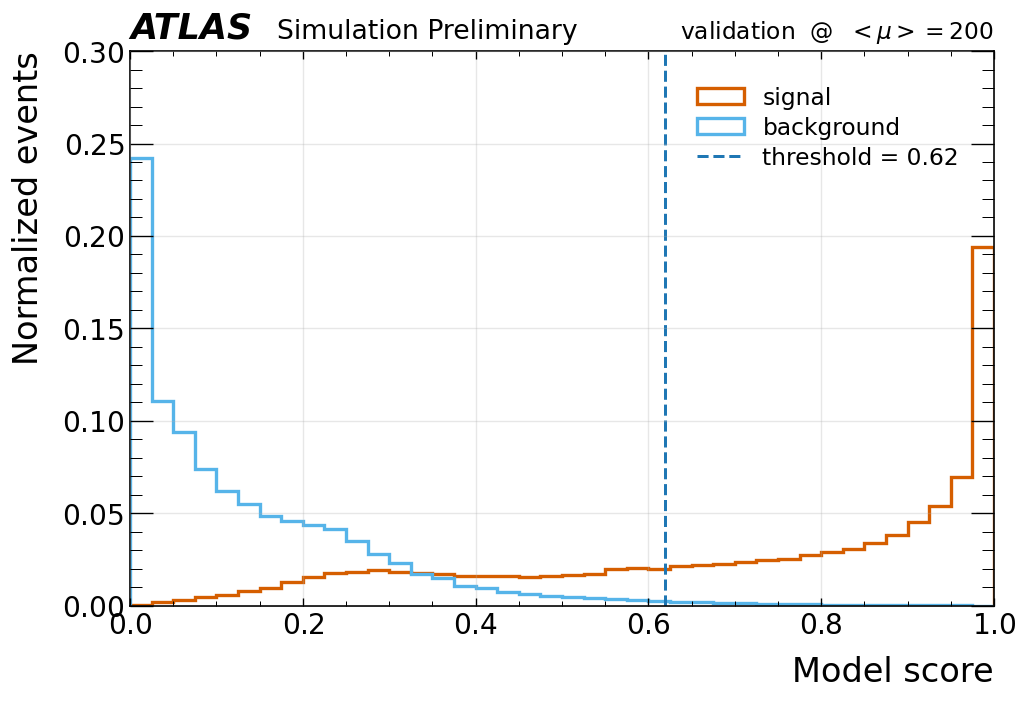

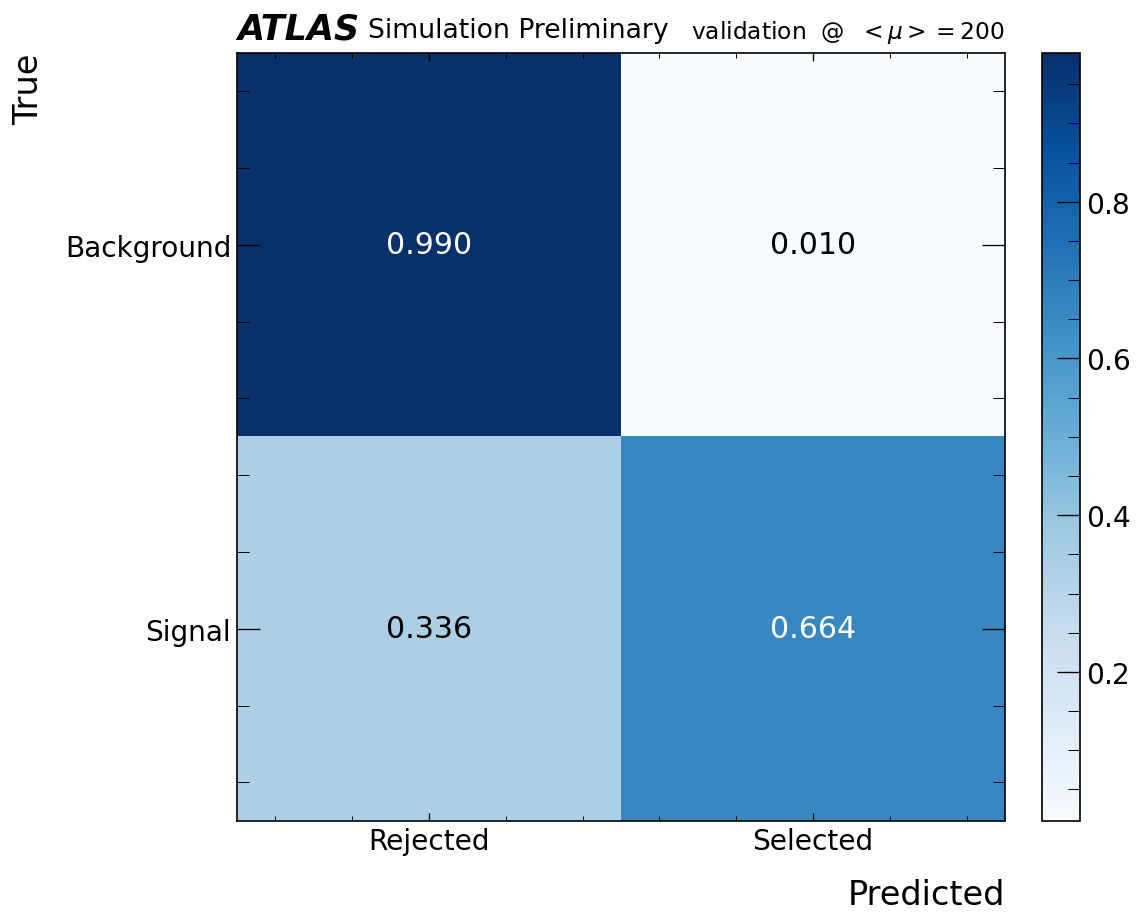

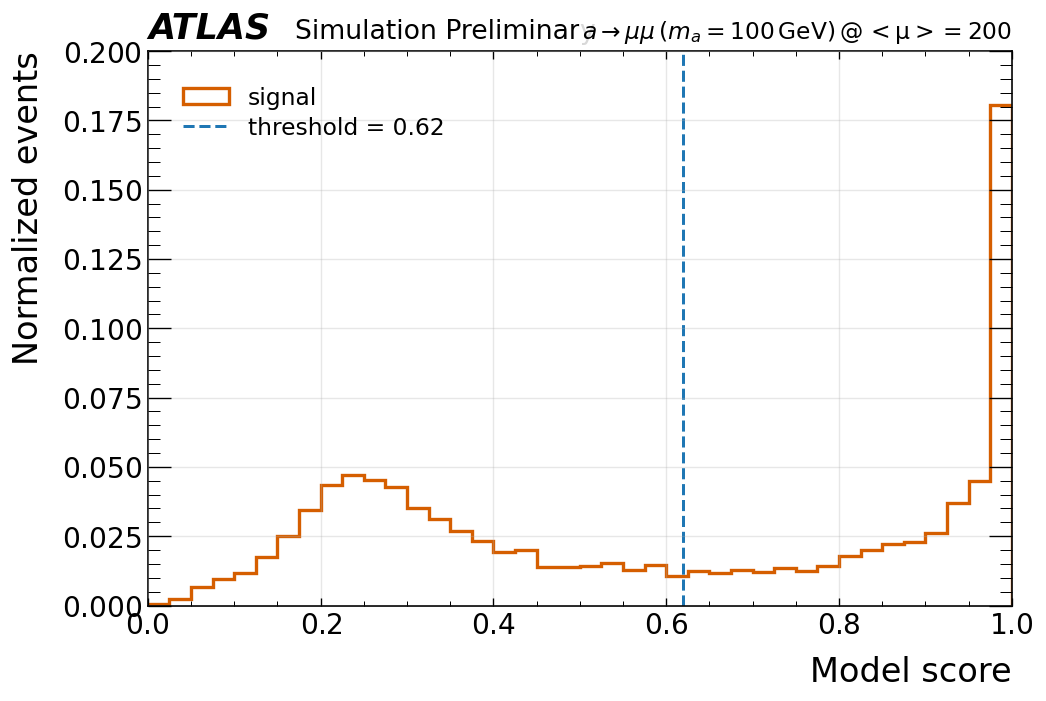

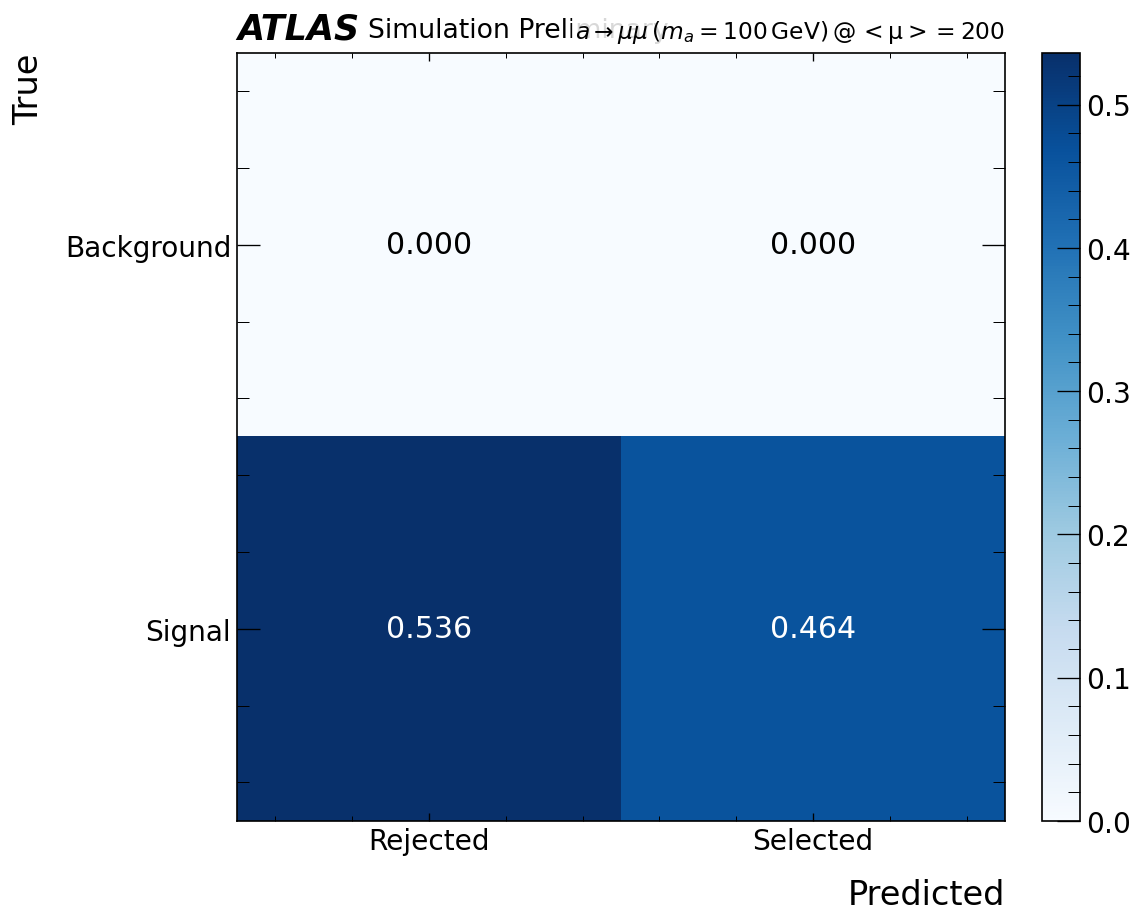

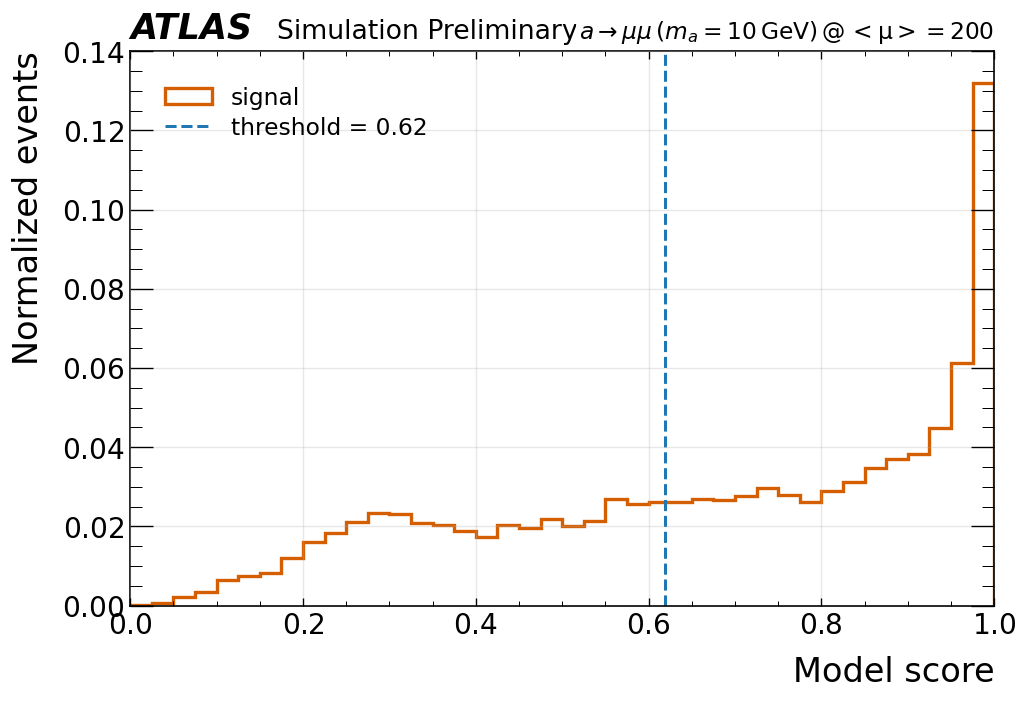

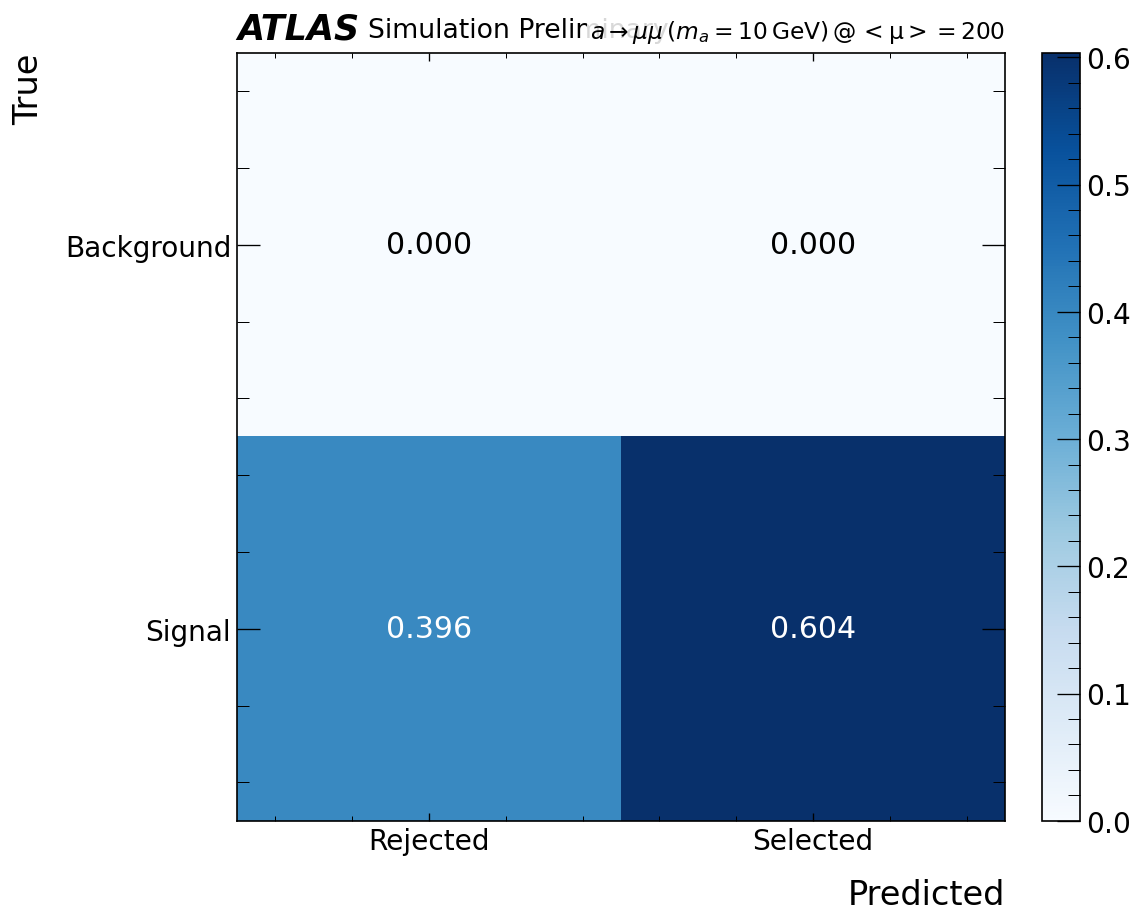

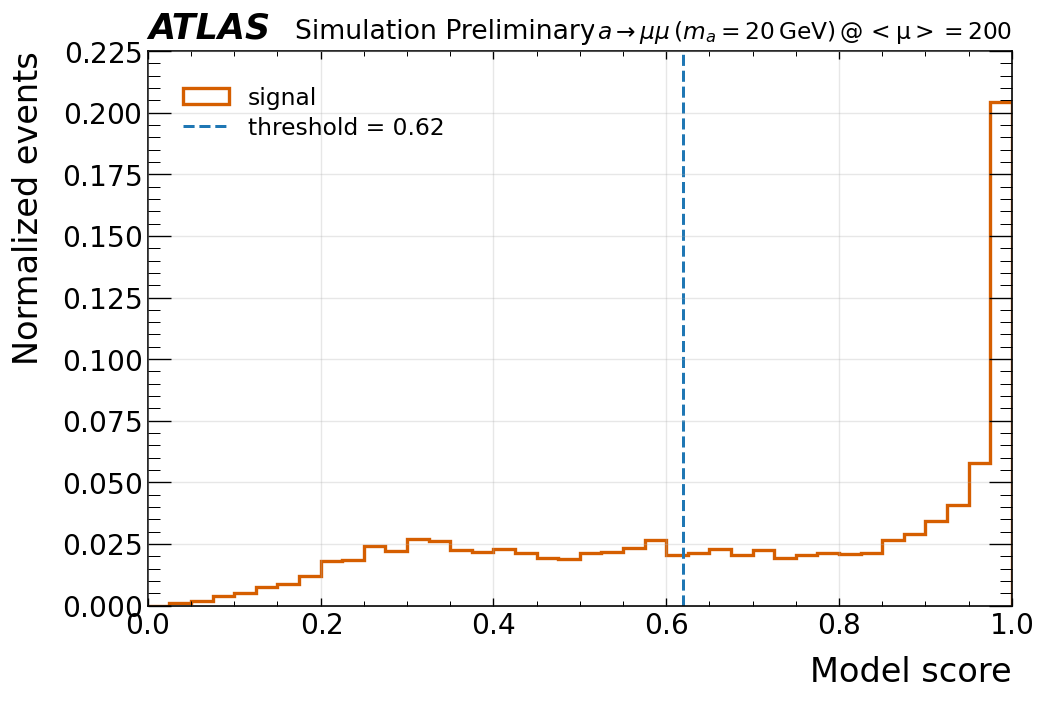

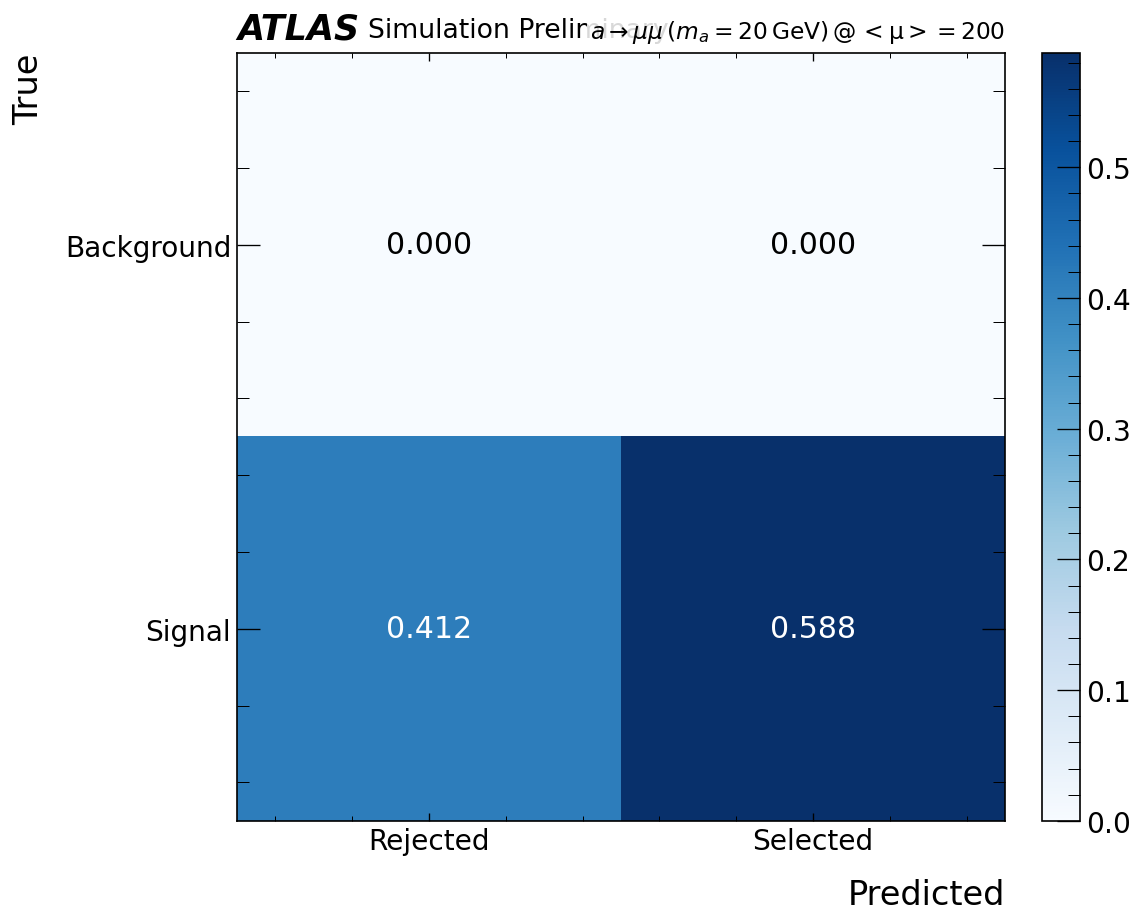

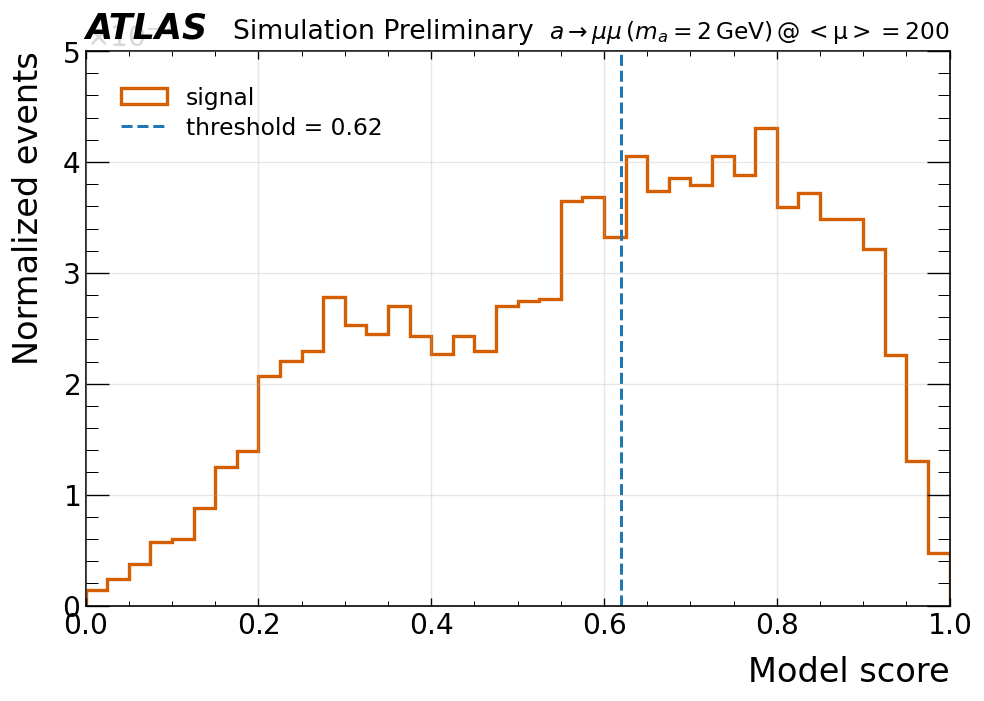

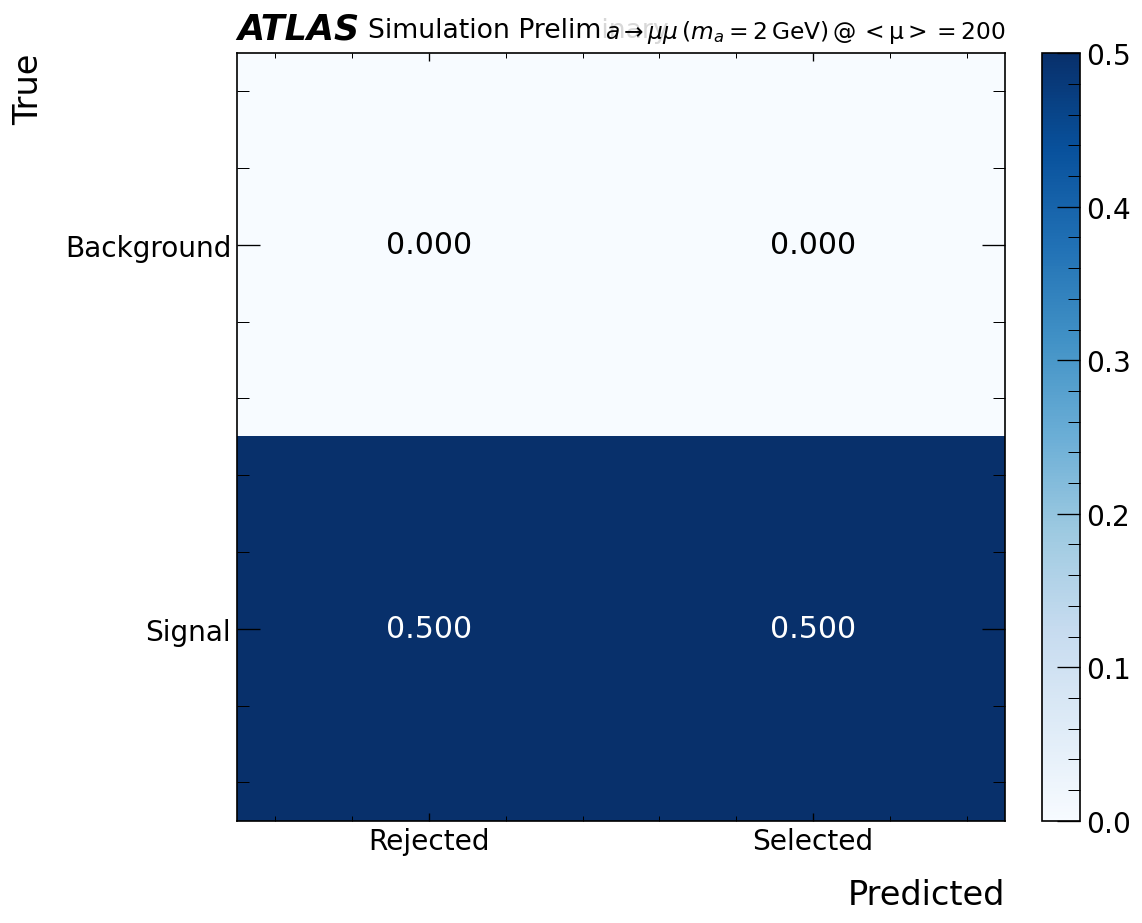

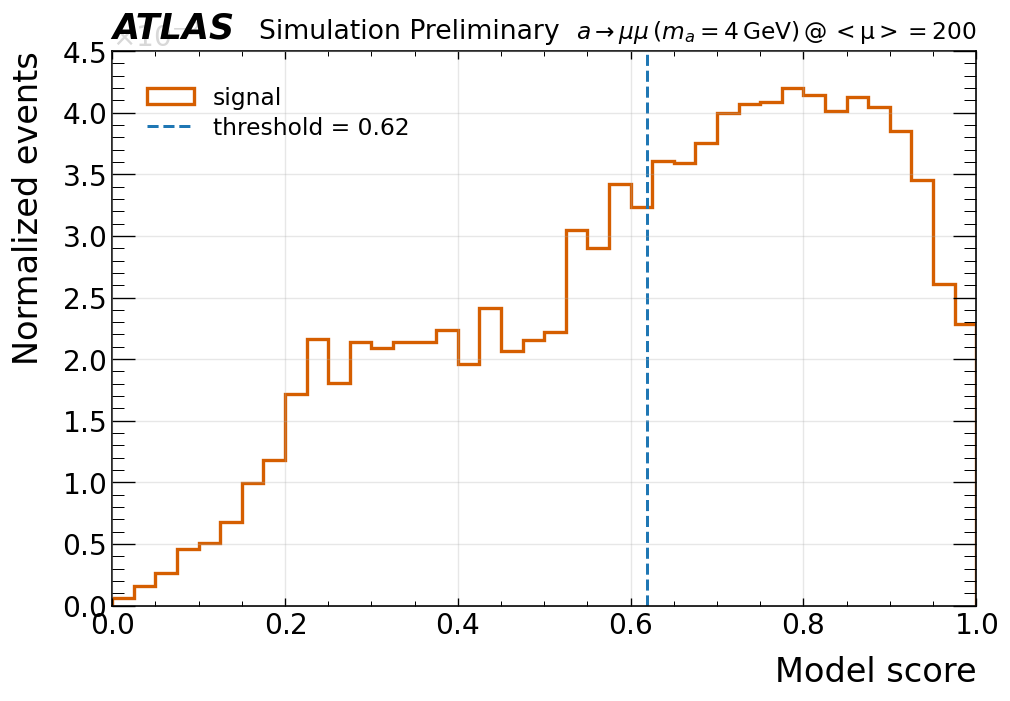

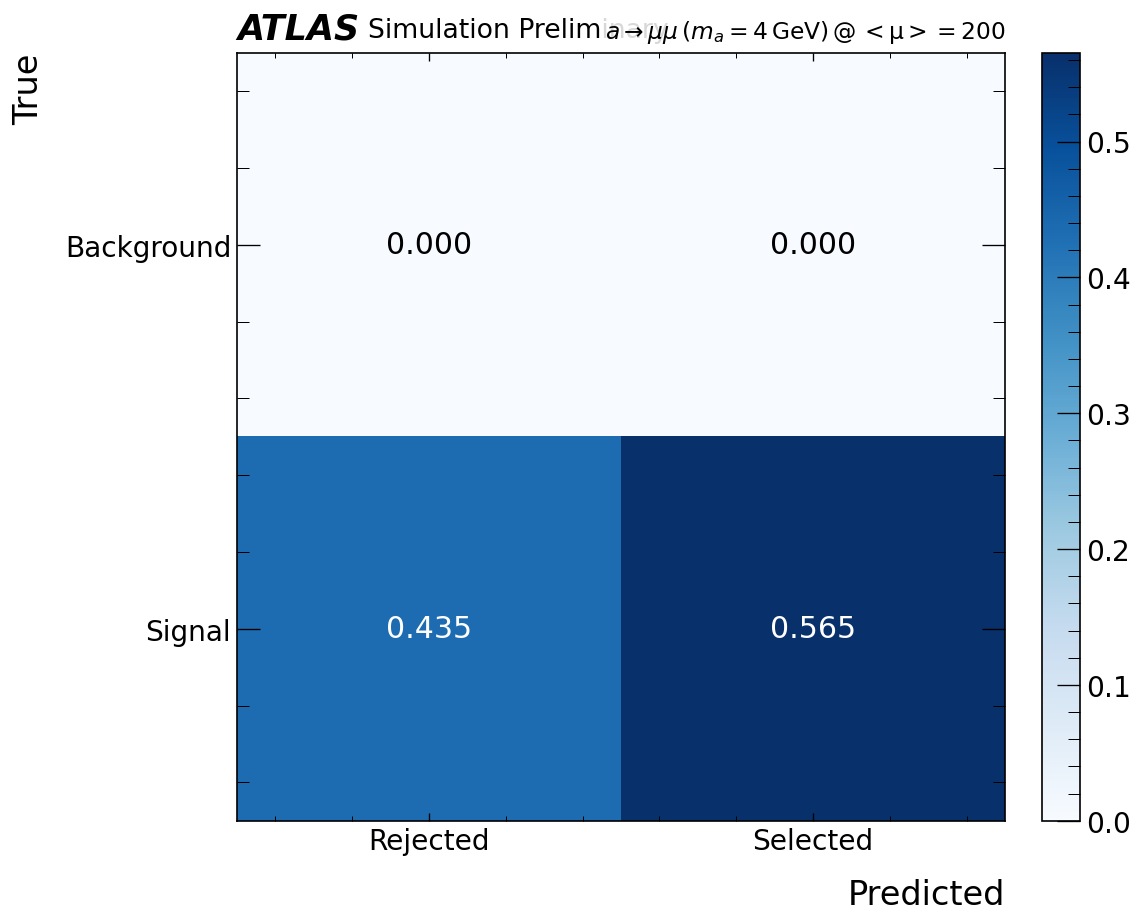

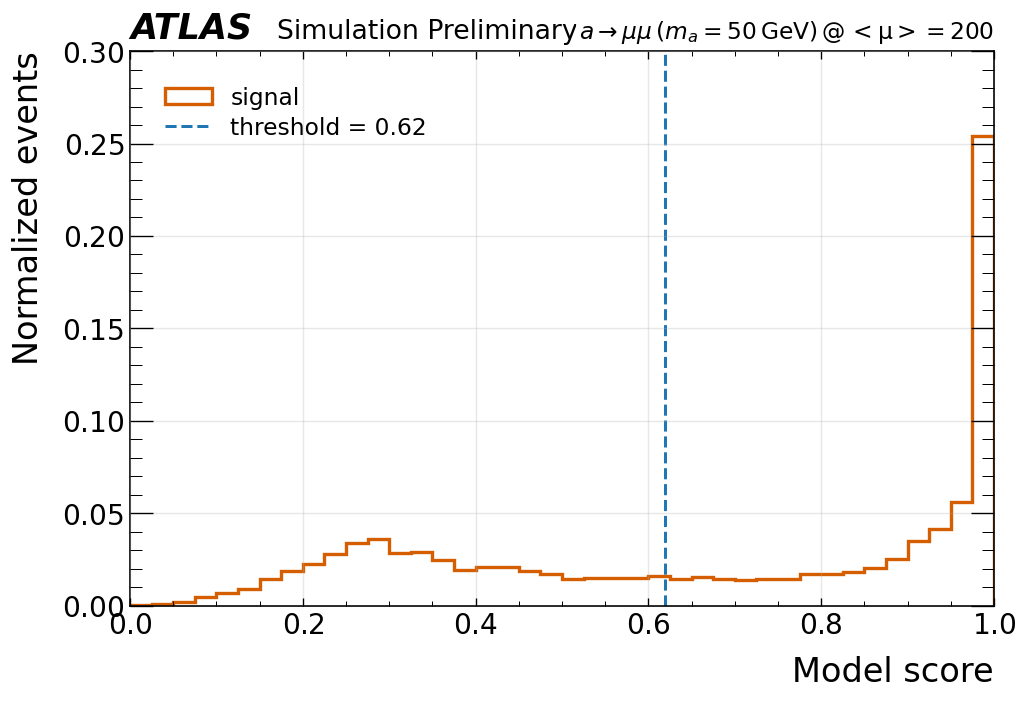

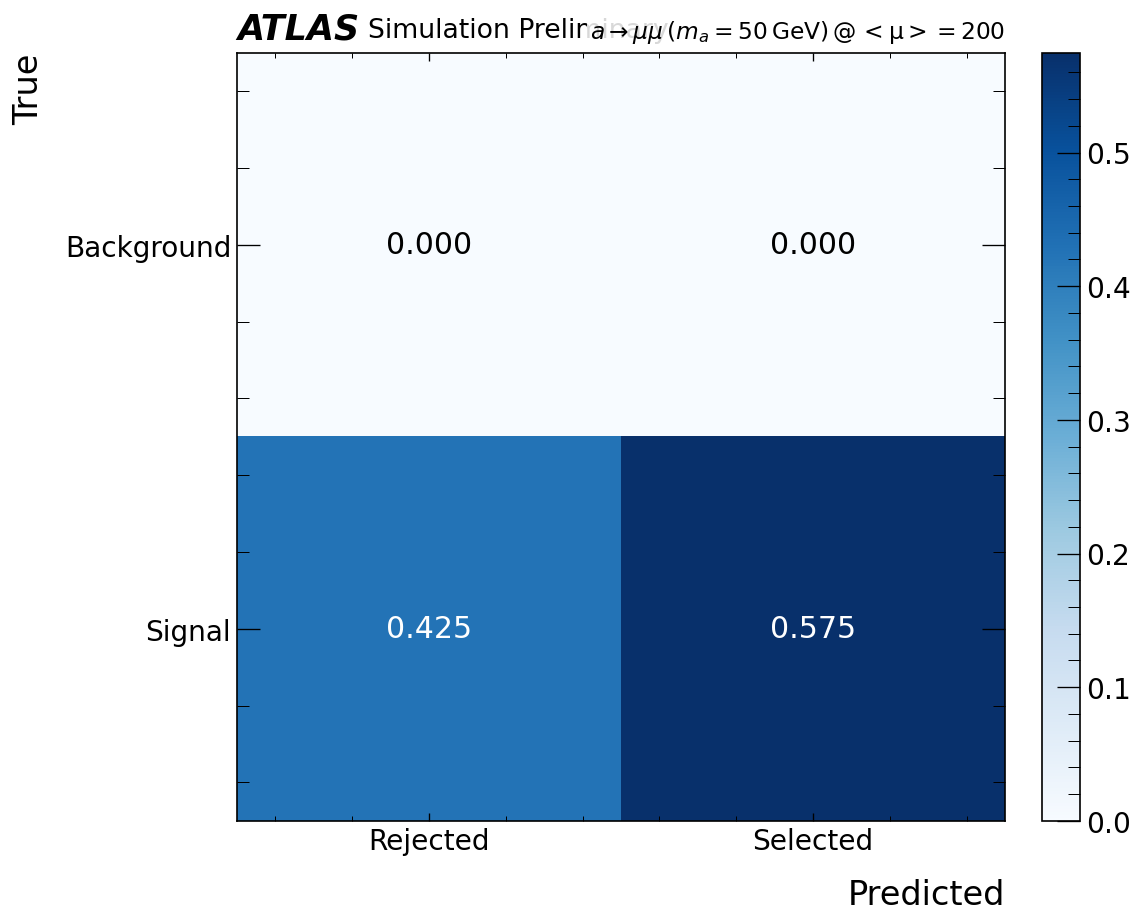

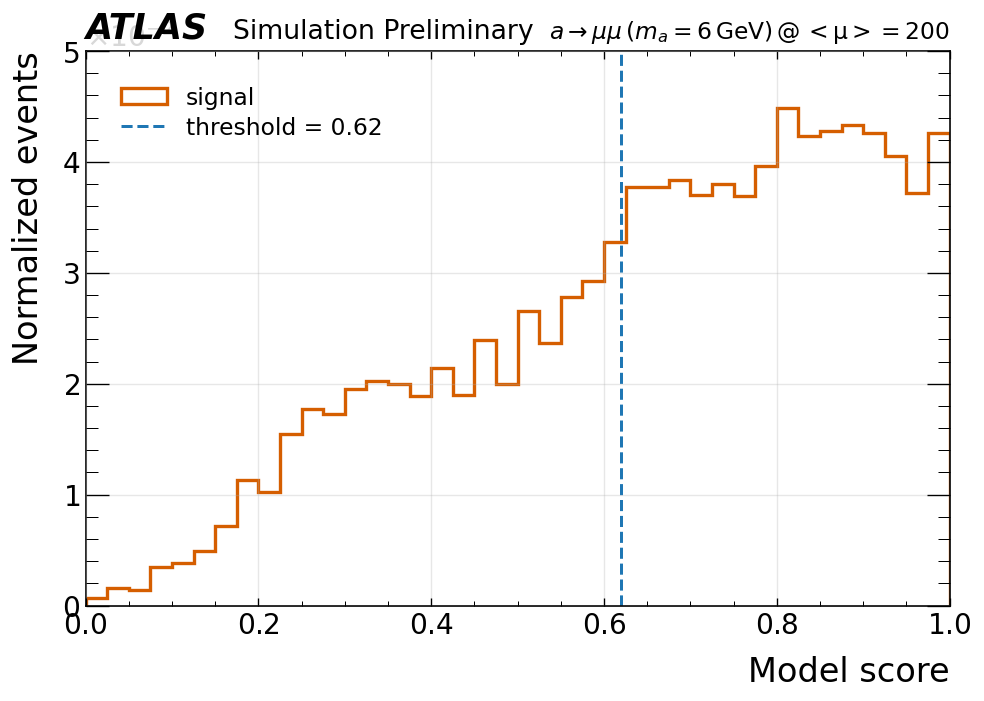

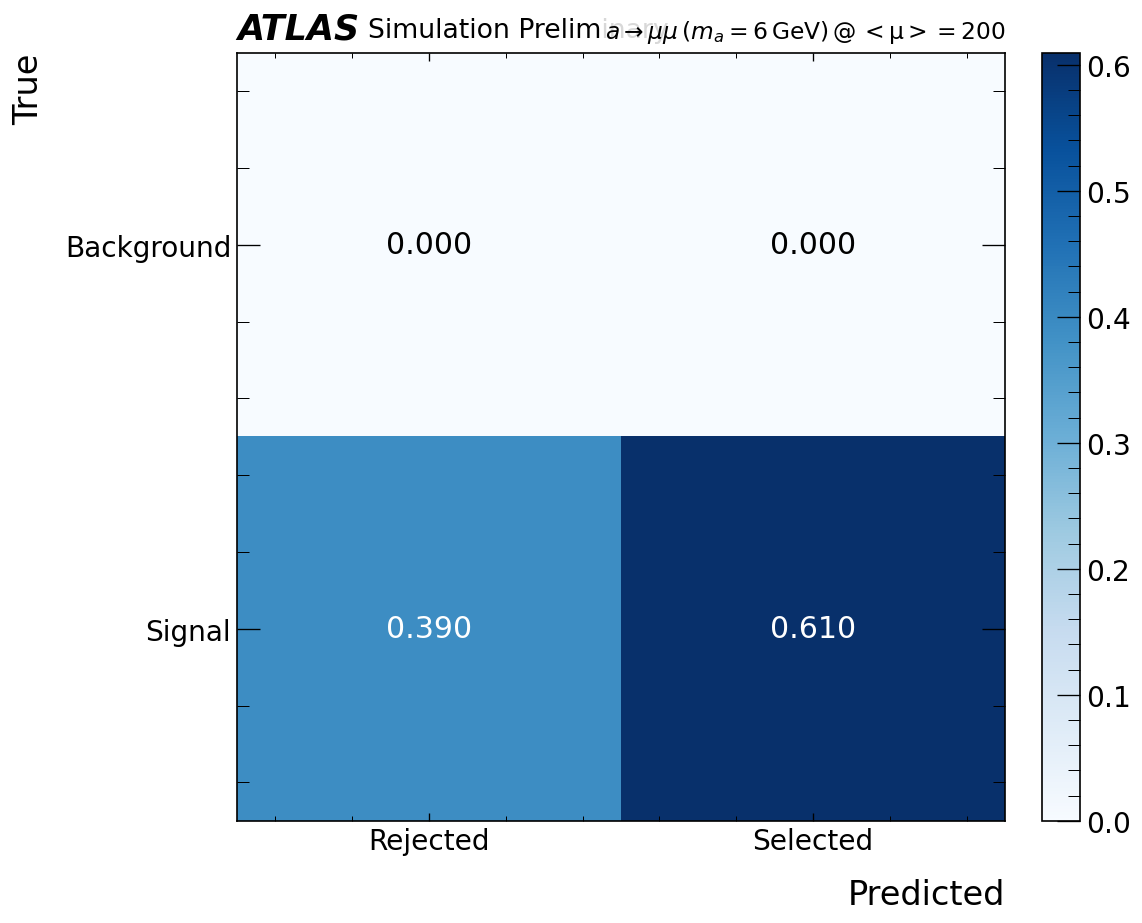

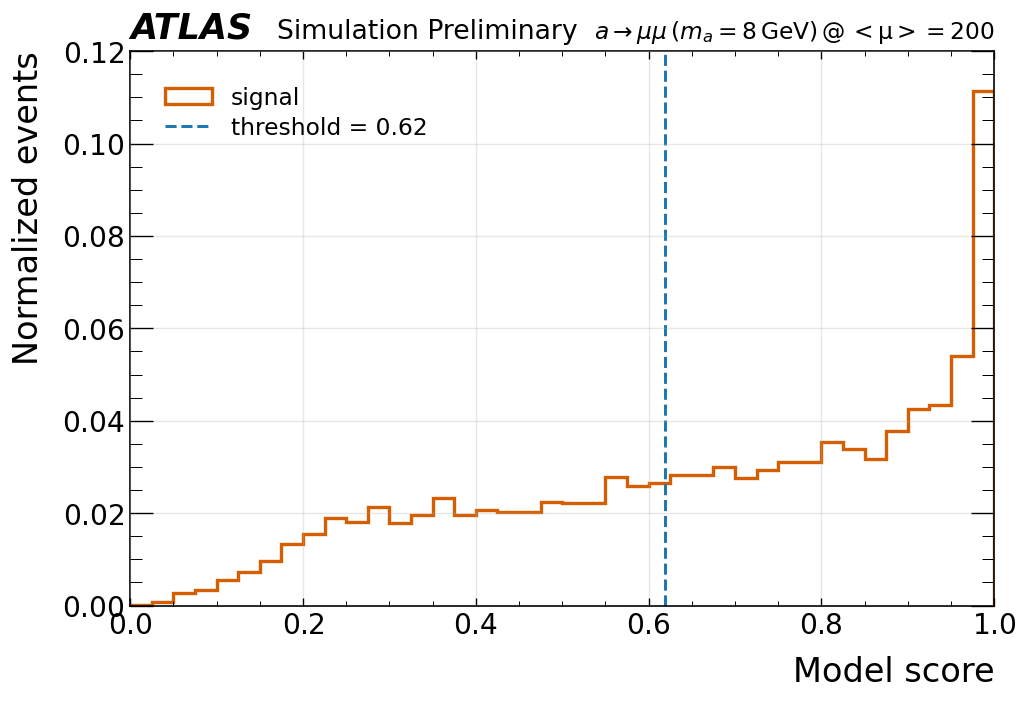

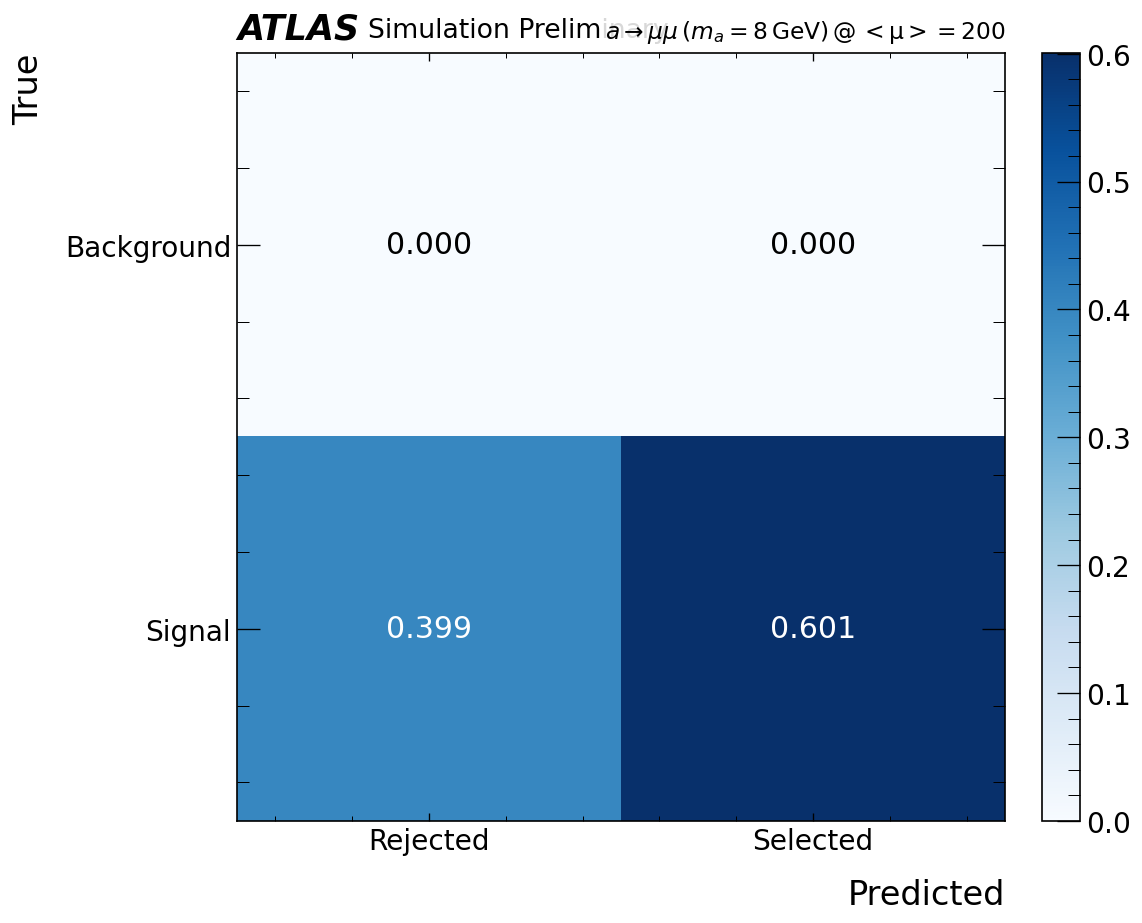

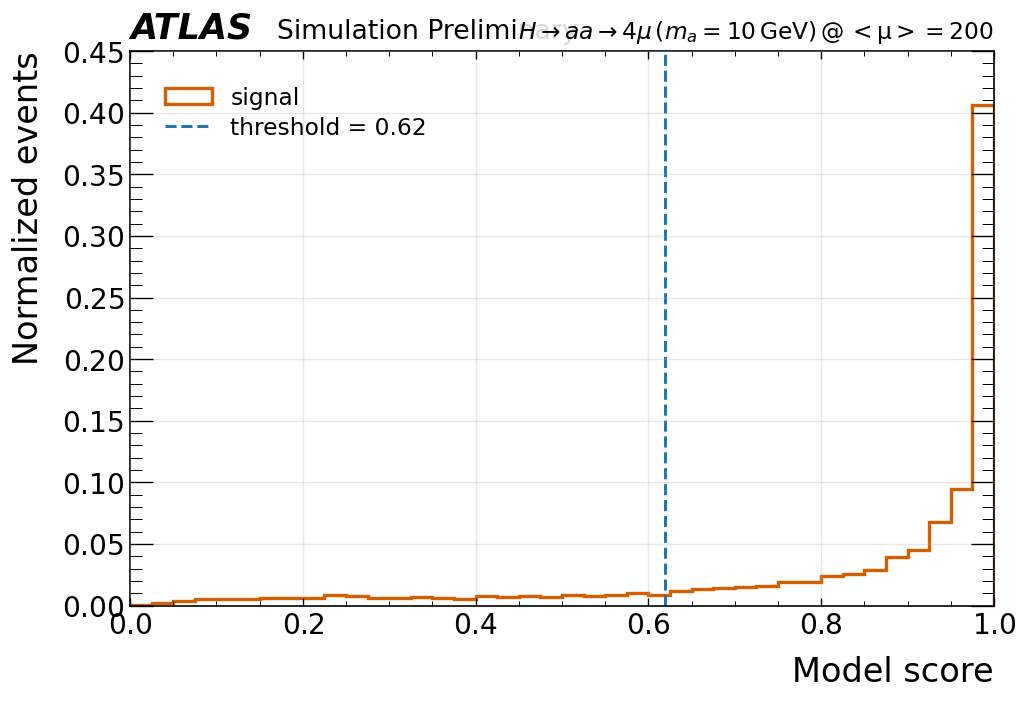

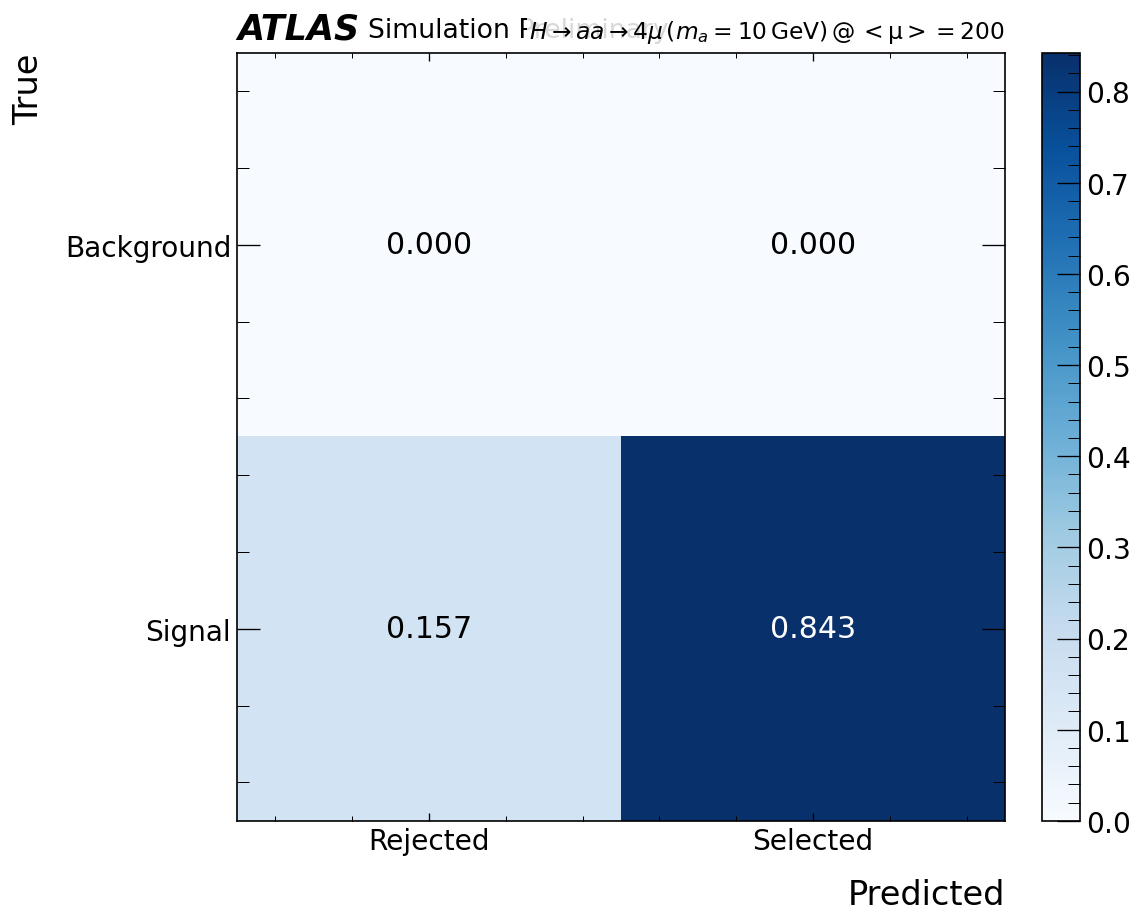

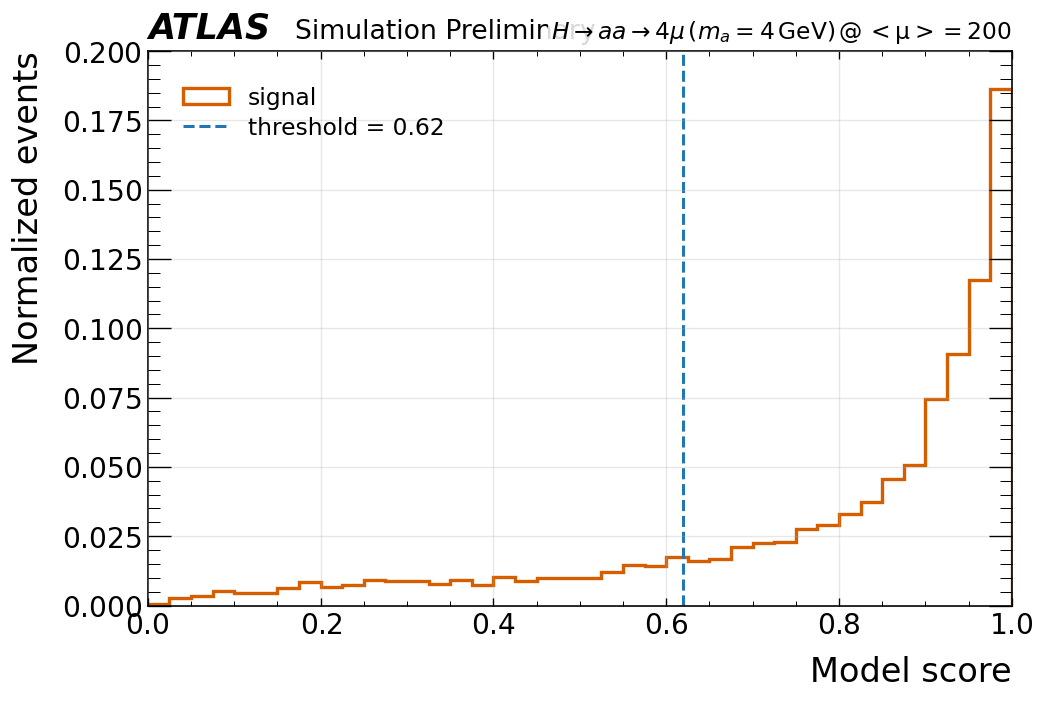

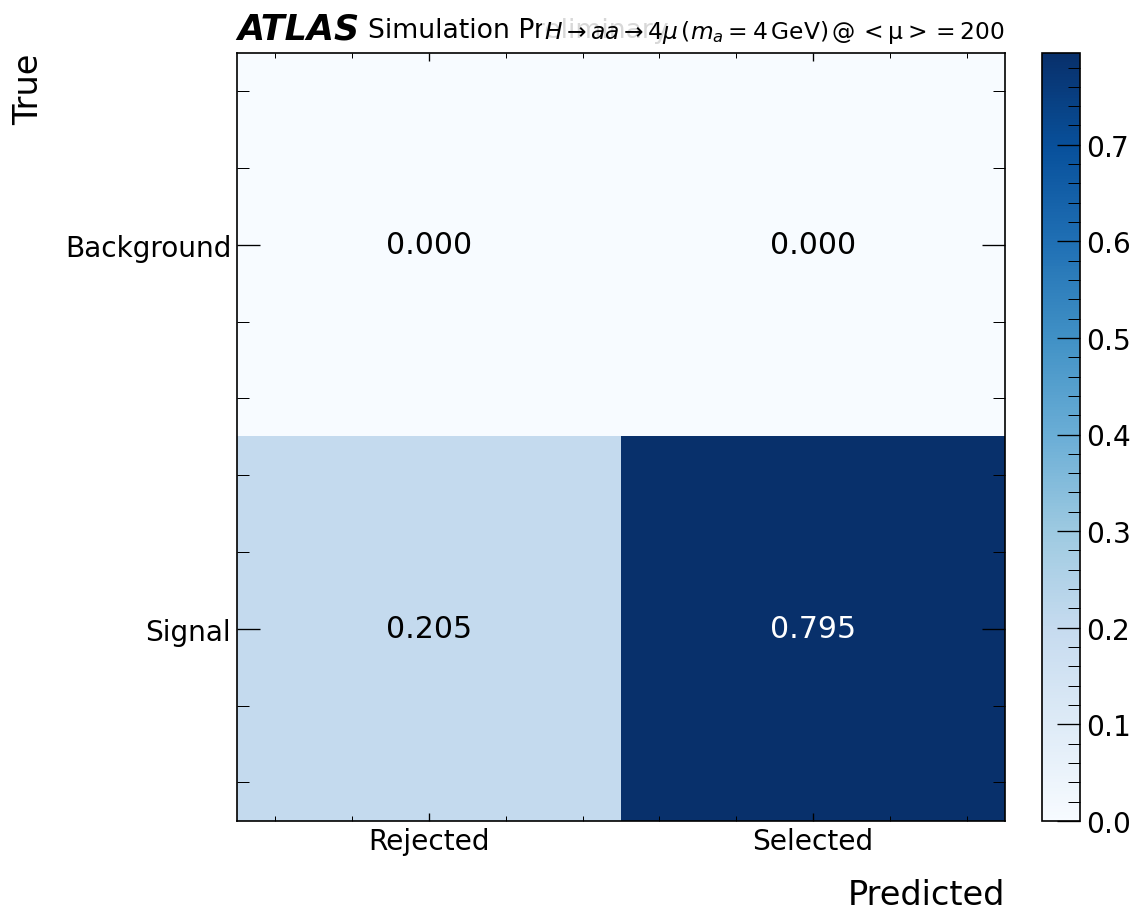

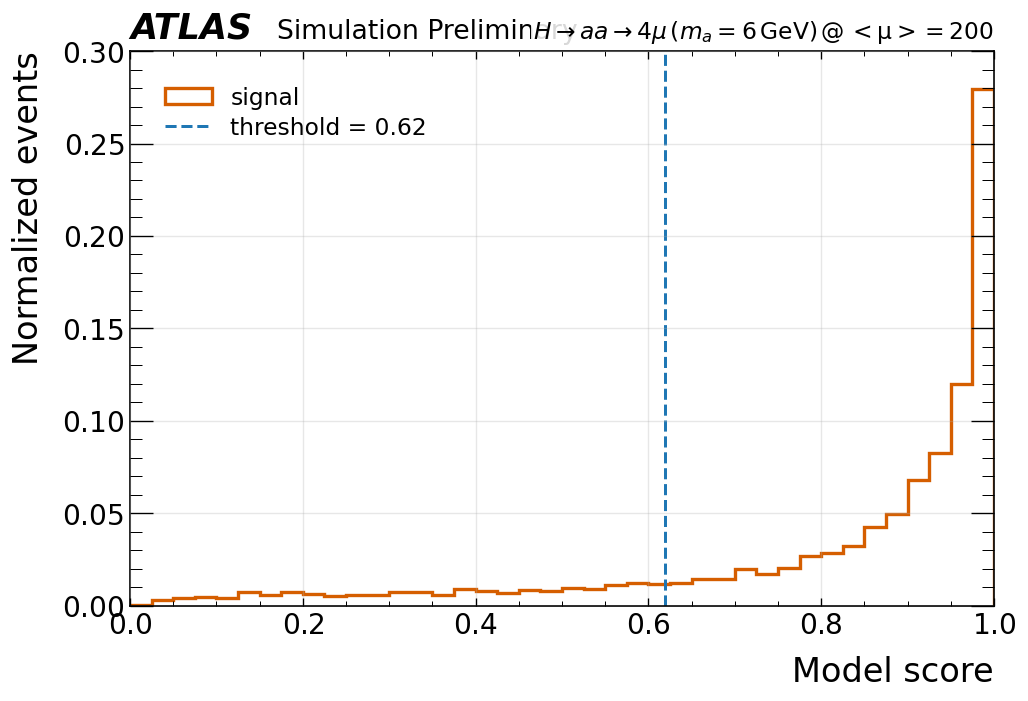

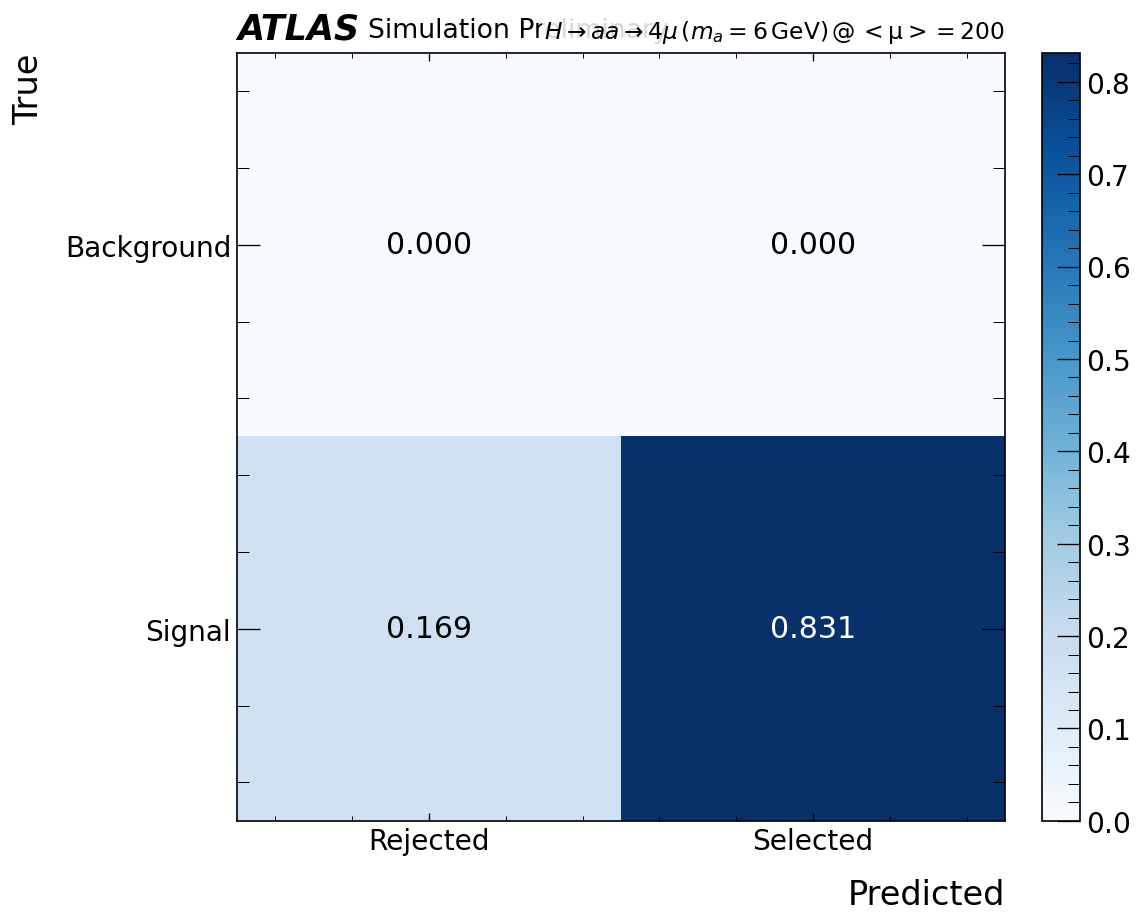

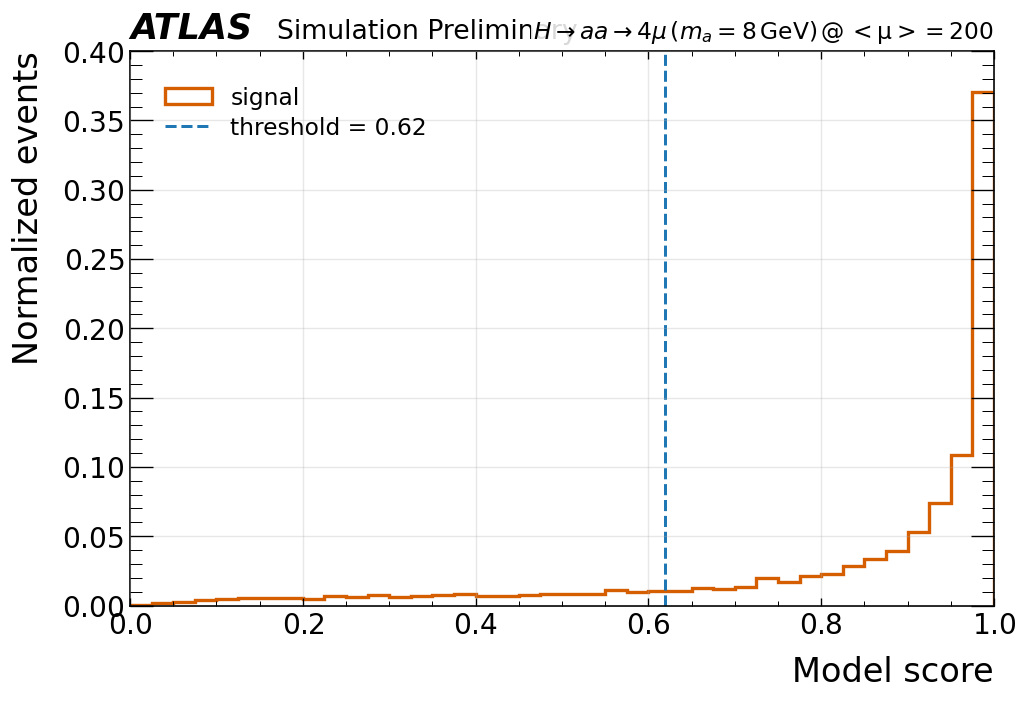

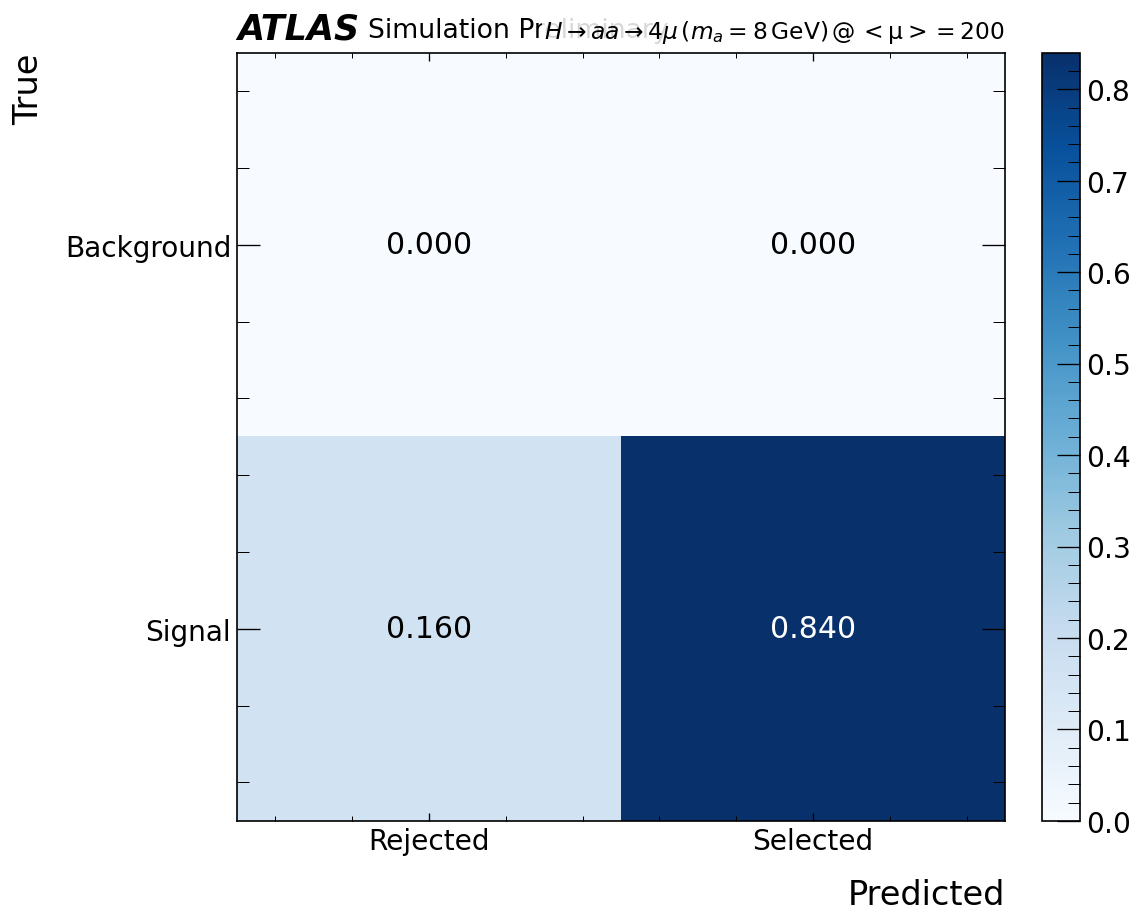

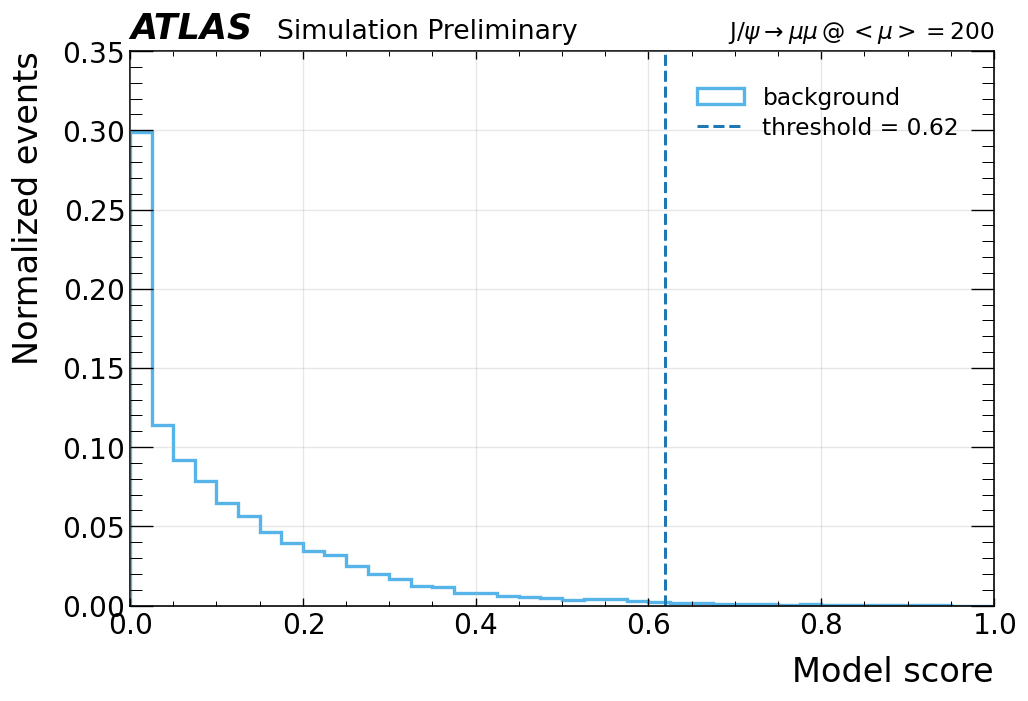

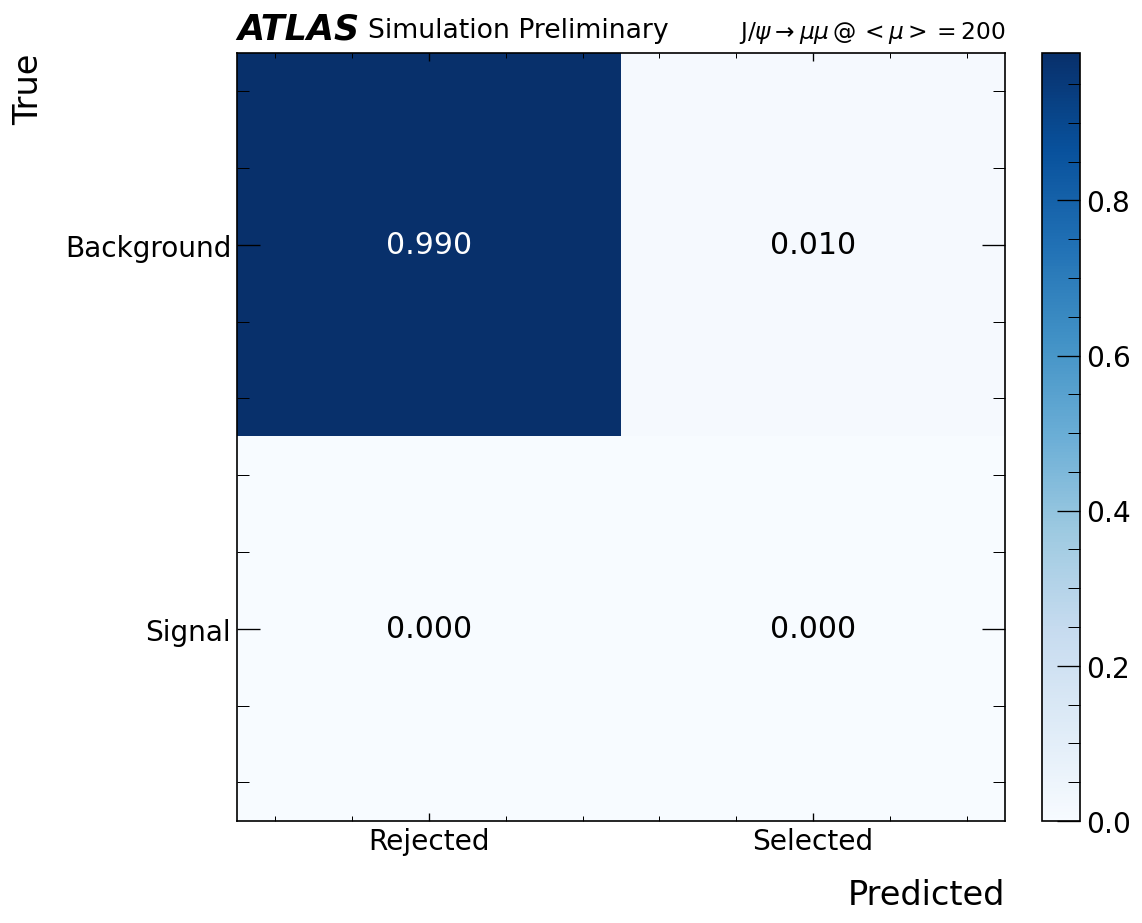

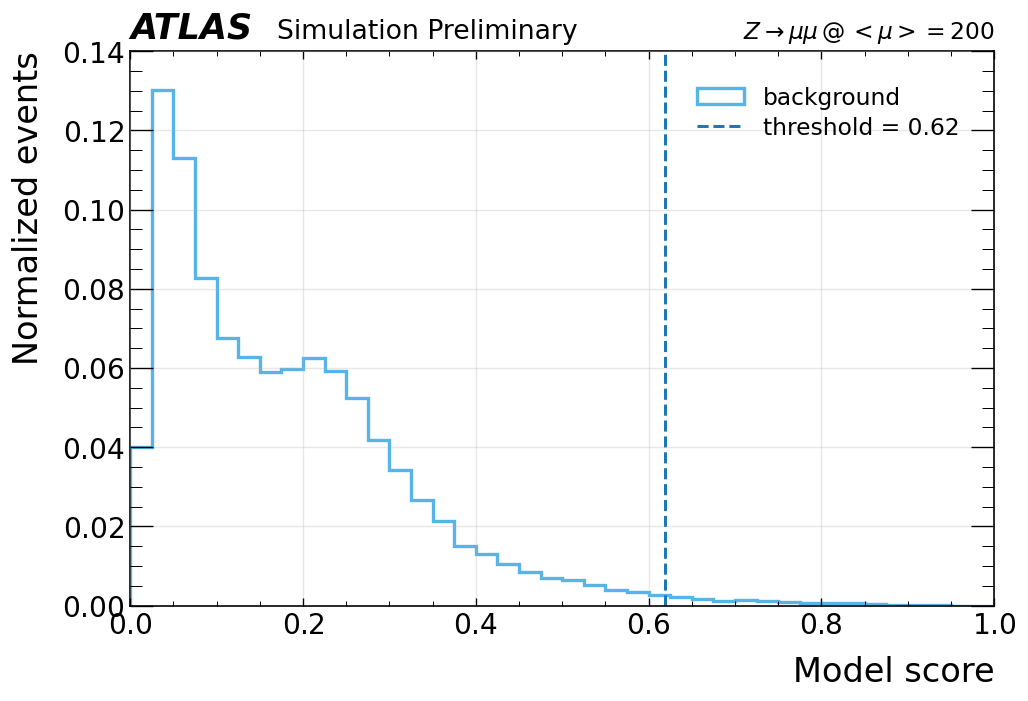

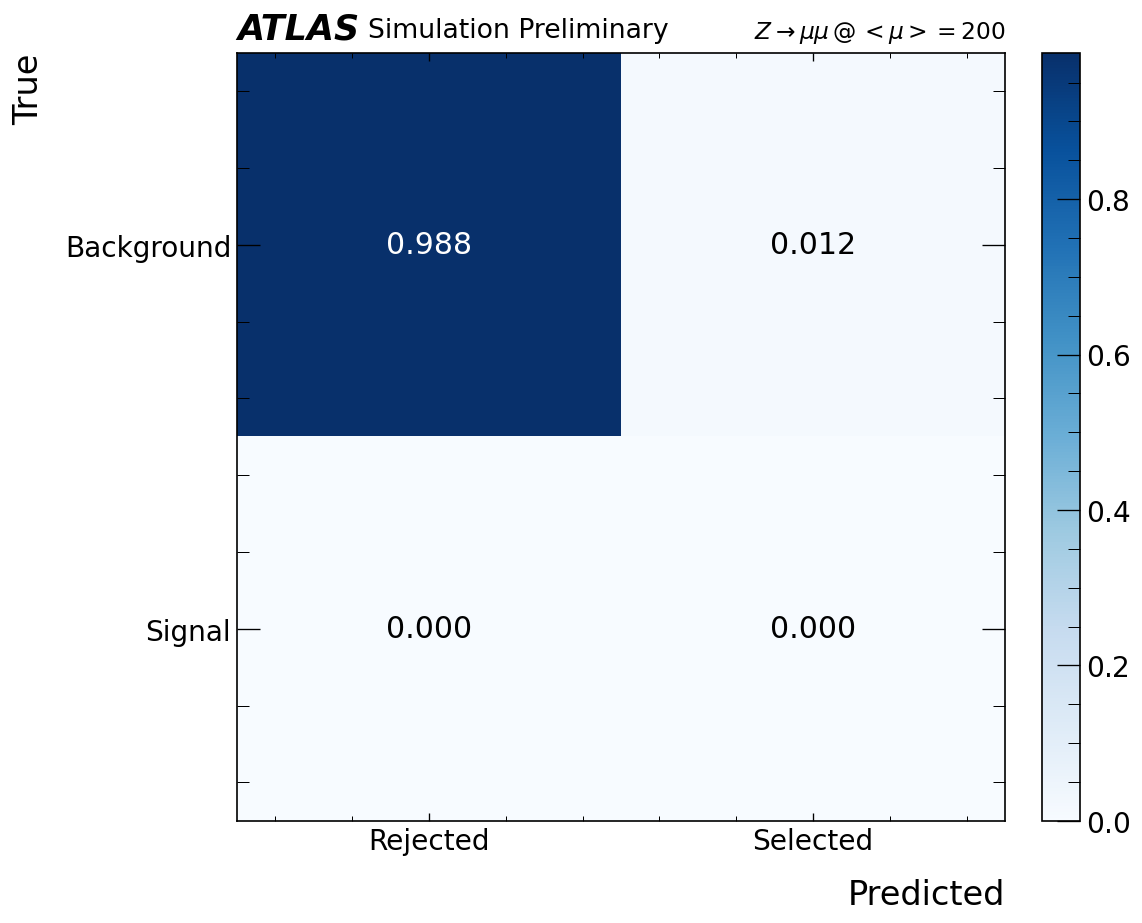

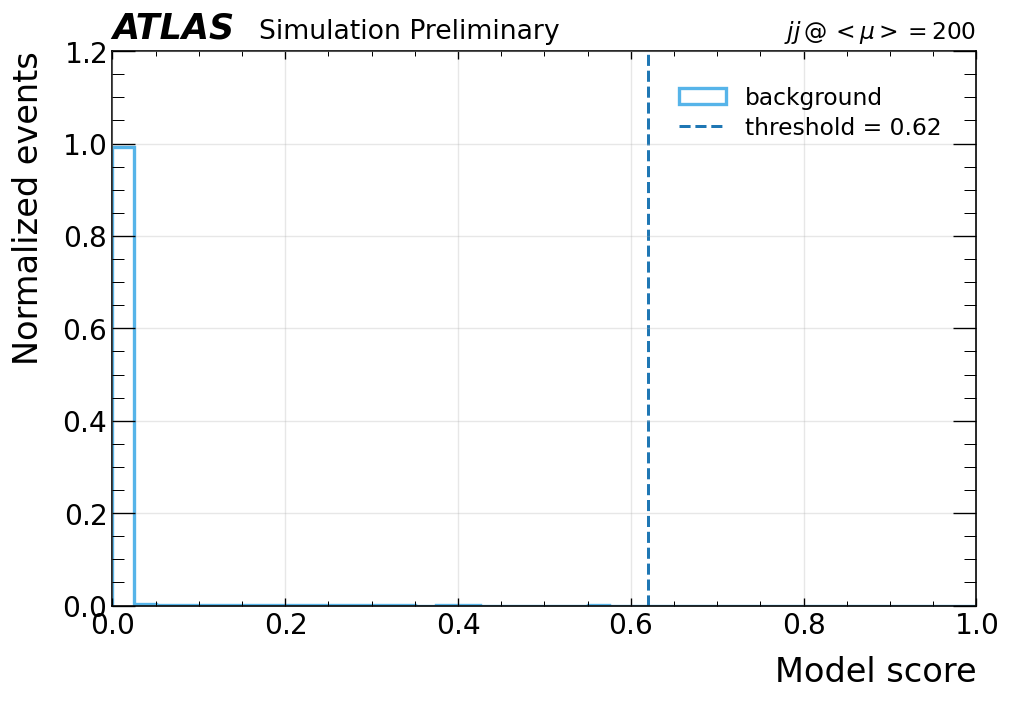

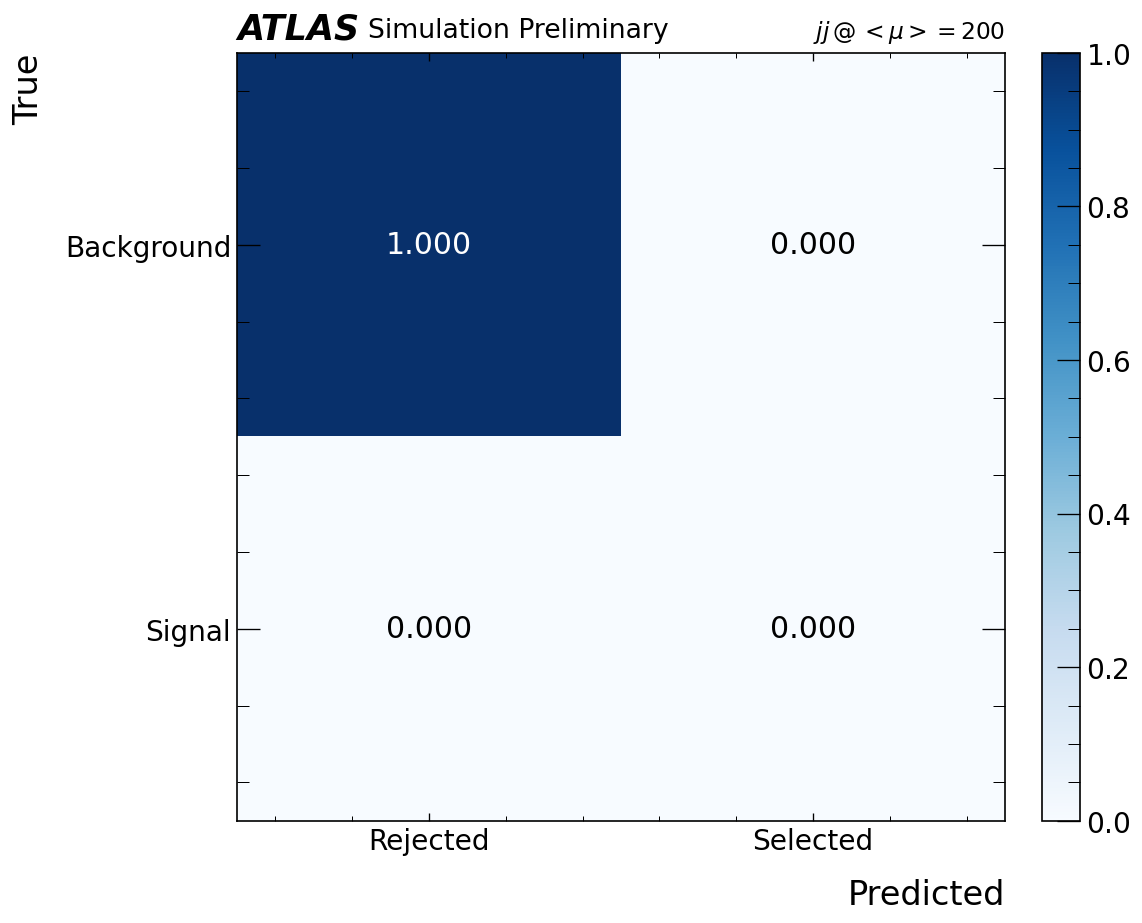

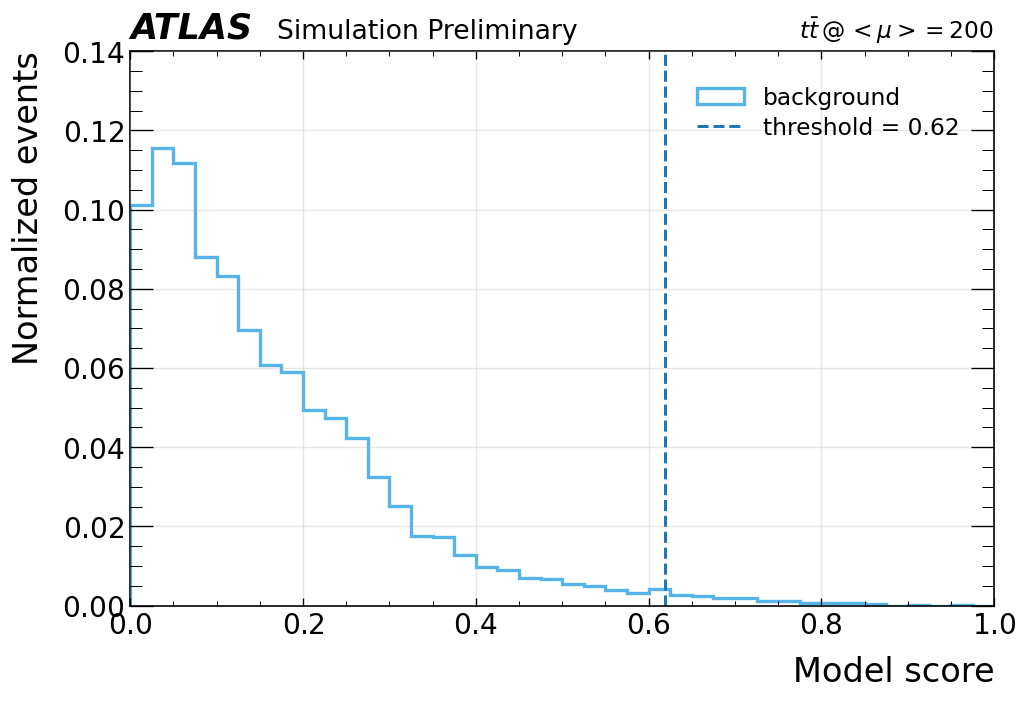

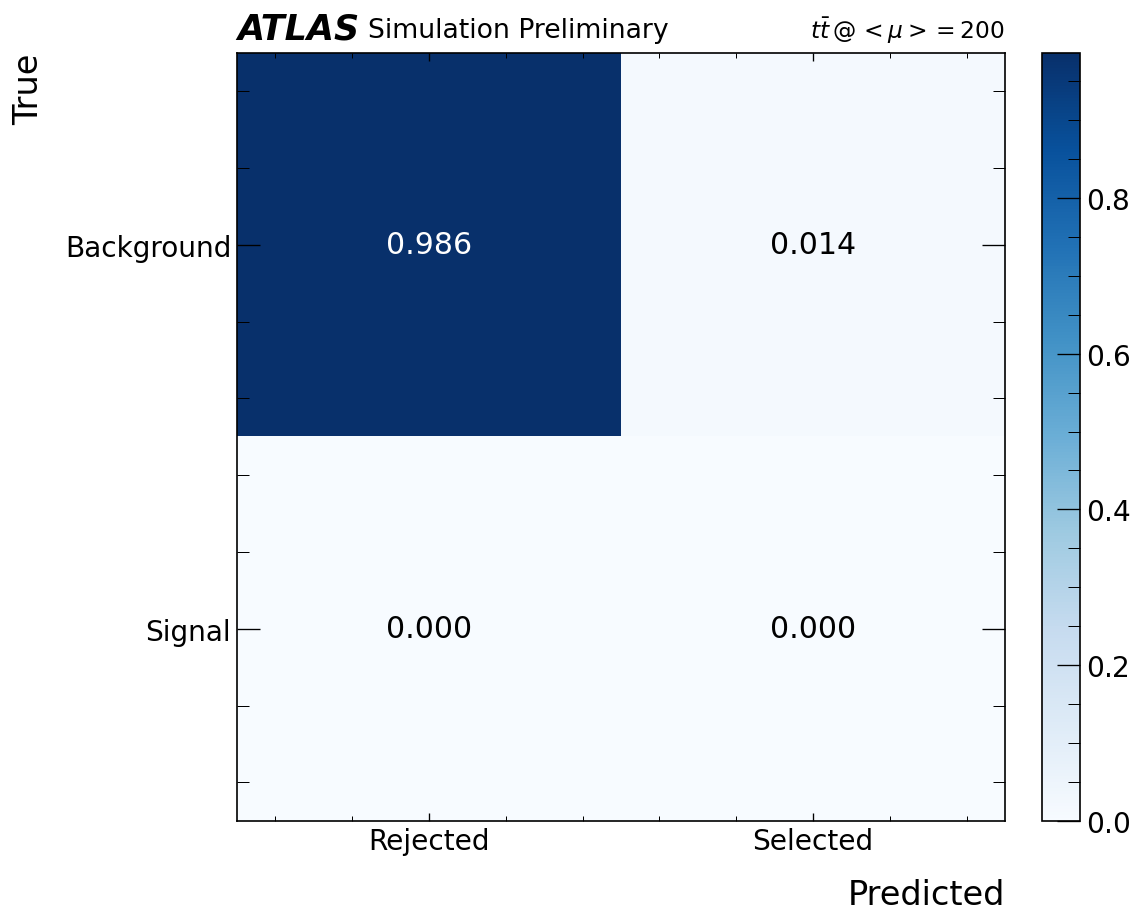

In [59]:
for this_sample in selected_samples:
    response_filename = (
        f"dv_response_{safe_filename(this_sample)}.png"
    )
    fig, ax = plot_best_model_score_response(
        best_entry,
        this_sample,
        threshold=best_threshold,
        normalize=True,
        n_plot_bins=N_RESPONSE_BINS,
        filename=response_filename,
    )
    if fig is not None:
        # save png and pdf
        plt.savefig(response_filename)
        plt.savefig(response_filename.replace(".png", ".pdf"))
        plt.show()
        plt.close(fig)

    # For "__all__", use the target-FPR counts selected above. All named samples
    # are evaluated at the same global FPR=0.01 threshold from their saved histograms.
    if this_sample == "__all__":
        cm_sample = cm_global
    else:
        cm_sample = confusion_matrix_from_saved_histogram(
            best_entry["samples"][this_sample],
            best_threshold,
        )

    cm_filename = (
        f"dv_{safe_filename(this_sample)}.png"
    )
    fig, ax = plot_confusion_matrix_atlas(
        cm_sample,
        normalize="row",
        class_names=("Rejected", "Selected"),
        sample_label=sample_label(this_sample),
        filename=cm_filename,
    )
    
    # save png and pdf
    plt.show()
    plt.close(fig)


In [60]:
from pathlib import Path
import subprocess
import shutil

tex = r"""
\documentclass[tikz,border=4mm]{standalone}
\usepackage{tikz-feynman}
\usepackage{xcolor}
\tikzfeynmanset{compat=1.1.0}

% Custom colours
\definecolor{MuonBlue}{RGB}{30,100,210}
\definecolor{PScalarRed}{RGB}{200,45,45}
\definecolor{GluonOrange}{RGB}{220,120,20}
\definecolor{HiggsBlack}{RGB}{20,20,20}

\begin{document}

\begin{tikzpicture}
\begin{feynman}

% Global vertex style
\tikzfeynmanset{
  every vertex/.style={font=\large},
}

% Incoming gluons
\vertex (g1) at (-3.7,  1.0) {\textcolor{GluonOrange}{$g$}};
\vertex (g2) at (-3.7, -1.0) {\textcolor{GluonOrange}{$g$}};

% Top-quark loop for gluon fusion
\vertex (t1) at (-1.8,  1.0);
\vertex (t2) at (-1.8, -1.0);
\vertex (t3) at (-0.3,  0.0);

% Higgs and pseudoscalar decay chain
\vertex (h)  at (1.2, 0.0) {$h$};

\vertex (a1) at (3.0,  1.2) {\textcolor{PScalarRed}{$a$}};
\vertex (a2) at (3.0, -1.2) {\textcolor{PScalarRed}{$a$}};

% Final-state muons
\vertex (mup1) at (5.0,  2.0) {\textcolor{MuonBlue}{$\mu^{+}$}};
\vertex (mum1) at (5.0,  0.4) {\textcolor{MuonBlue}{$\mu^{-}$}};

\vertex (mup2) at (5.0, -0.4) {\textcolor{MuonBlue}{$\mu^{+}$}};
\vertex (mum2) at (5.0, -2.0) {\textcolor{MuonBlue}{$\mu^{-}$}};

% Diagram
\diagram*{
  % Gluon fusion
  (g1) -- [gluon, draw=GluonOrange, line width=1.1pt] (t1),
  (g2) -- [gluon, draw=GluonOrange, line width=1.1pt] (t2),

  % Top-quark loop: orange
  (t1) -- [fermion, draw=GluonOrange, line width=1.0pt,
           edge label=\textcolor{GluonOrange}{$t$}] (t3),
  (t3) -- [fermion, draw=GluonOrange, line width=1.0pt,
           edge label=\textcolor{GluonOrange}{$t$}] (t2),
  (t2) -- [fermion, draw=GluonOrange, line width=1.0pt,
           edge label=\textcolor{GluonOrange}{$t$}] (t1),

  % Higgs line: neutral colour
  (t3) -- [scalar, dashed, draw=HiggsBlack, line width=1.1pt] (h),

  % Pseudoscalar lines: red dashed
  (h) -- [scalar, dashed, draw=PScalarRed, line width=1.2pt] (a1),
  (h) -- [scalar, dashed, draw=PScalarRed, line width=1.2pt] (a2),

  % Muons: blue fermion lines
  (a1) -- [fermion, draw=MuonBlue, line width=1.2pt] (mup1),
  (a1) -- [anti fermion, draw=MuonBlue, line width=1.2pt] (mum1),

  (a2) -- [fermion, draw=MuonBlue, line width=1.2pt] (mup2),
  (a2) -- [anti fermion, draw=MuonBlue, line width=1.2pt] (mum2),
};

\end{feynman}

% Optional process label
\node[font=\large] at (0,-2.65)
  {$gg \rightarrow h \rightarrow aa \rightarrow 4\mu$};

\end{tikzpicture}

\end{document}
"""

outdir = Path("feynman_h_aa_4mu")
outdir.mkdir(exist_ok=True)

tex_path = outdir / "gg_h_aa_4mu_colored.tex"
tex_path.write_text(tex)

print(f"Wrote {tex_path}")

if shutil.which("lualatex"):
    subprocess.run(
        ["lualatex", "-interaction=nonstopmode", tex_path.name],
        cwd=outdir,
        check=True,
    )
    print(f"Compiled PDF: {outdir / 'gg_h_aa_4mu_colored.pdf'}")
else:
    print("lualatex not found. Compile the .tex file manually with lualatex.")

Wrote feynman_h_aa_4mu/gg_h_aa_4mu_colored.tex
This is LuaHBTeX, Version 1.18.0 (TeX Live 2024) 
 restricted system commands enabled.
(./gg_h_aa_4mu_colored.tex
LaTeX2e <2024-11-01> patch level 2
L3 programming layer <2025-01-18>
 (/usr/local/texlive/2024/texmf-dist/tex/latex/standalone/standalone.cls
Document Class: standalone 2022/10/10 v1.3b Class to compile TeX sub-files stan
dalone
(/usr/local/texlive/2024/texmf-dist/tex/latex/tools/shellesc.sty)
(/usr/local/texlive/2024/texmf-dist/tex/generic/iftex/ifluatex.sty
(/usr/local/texlive/2024/texmf-dist/tex/generic/iftex/iftex.sty))
(/usr/local/texlive/2024/texmf-dist/tex/latex/xkeyval/xkeyval.sty
(/usr/local/texlive/2024/texmf-dist/tex/generic/xkeyval/xkeyval.tex
(/usr/local/texlive/2024/texmf-dist/tex/generic/xkeyval/xkvutils.tex
(/usr/local/texlive/2024/texmf-dist/tex/generic/xkeyval/keyval.tex))))
(/usr/local/texlive/2024/texmf-dist/tex/latex/standalone/standalone.cfg)
(/usr/local/texlive/2024/texmf-dist/tex/latex/base/article.cls
D